# Notebook Guide — Main Sections


This guide lists the main titles and the purpose of each section.

1. **Project Overview** — project title, problem statement, scope, and expected outcomes.
2. **Introduction** — background, motivation, synthetic dataset justification, and limitations.
3. **Project Objectives and Research Questions** — objectives, RQ1–RQ9, neighboring-cell information, and shared-site/cascading failures.
4. **Project Workflow — Steps 1–8** — concise methodology overview; detailed Python implementation is in Section 6.
5. **Responses to Previous Feedback** — professor concerns, project responses, supporting evidence, and remaining limitations.
6. **Data Analysis and Modeling Implementation** — EDA (6.1–6.2), additional analyses for the professor's comments (6.2 Additional: outage timing, availability, pre-outage signal, neighbor impact), preprocessing (6.3), features (6.4), target + split + class balance (6.5–6.6), models (6.7), evaluation with tuned rule baselines and diagnostics (6.8), neighbor/shared-site experiment (6.9).
7. **Progress and Preliminary Results** — only findings supported by code that has actually run and whose outputs have been checked; unrun work is marked Pending.
8. **Next Steps and Project Completion Plan** — remaining coding, debugging, experiments, validation, and submission preparation.
9. **Conclusion** — verified findings, answers to research questions, contributions, and limitations.

# 1. Project Overview

**Project title:** Mobile Network Performance Monitoring, Outage Impact Analysis, and Future Cell Outage Prediction

## Problem and motivation
Mobile networks provide essential communication services, but cell outages, high network load, equipment faults, power failures, and connectivity problems can reduce service availability and user experience. When a cell becomes unavailable, traffic and users may move to neighboring cells, increasing their load. This project examines network KPI behavior, outage impact, and whether available information can help predict a new cell outage.

## Project aim
The aim is to use Python-based data analysis and machine learning to monitor mobile network performance, analyze the impact of cell outages, and predict whether a new cell outage will begin within the next 12 hours.

## Datasets
The project uses two synthetic datasets representing a mobile network environment in Uganda for **1 January 2024 to 31 December 2025**, with KPI records designed at three-hour intervals.

- **Dataset 1 — Site/Cell Information:** Site_ID, Cell_ID, technology, region, township/district fields, and neighboring-cell relationships.
- **Dataset 2 — KPI and Event Records:** timestamped KPI observations, alarm counts, and OUTAGE/RECOVERY event records.

The datasets are synthetically generated, informed by the author's previous telecommunications-industry experience and understanding of KPI-oriented data structures. They are **not actual records from a Ugandan or other telecommunications operator**. This controlled design supports reproducible analysis, but results cannot automatically be generalized to live networks.

## Proposed methodology
The project will inspect and prepare the datasets, engineer features from information available before prediction time, construct the `Outage_Next_12h` label, use chronological and unseen-site evaluation, and compare threshold-based warning rules with Logistic Regression and Random Forest. Neighboring-cell features will be evaluated separately where the dataset represents those relationships.

# 2. Introduction

Mobile networks are complex systems whose performance can be affected by outages, congestion, equipment faults, power failures, and backhaul or connectivity problems. Such incidents can reduce service availability and affect users. They may also shift traffic to neighboring cells, potentially increasing load and changing throughput, latency, and packet loss in those cells.

The motivation for this project comes partly from the author's previous work experience in telecommunications, where network datasets containing a wide range of Key Performance Indicators (KPIs) were encountered. Publicly available datasets do not always combine KPI time series, site/cell metadata, neighbor relationships, and outage/recovery events in a single resource. For this reason, synthetic datasets were created to bring together the information needed for this study.

The synthetic dataset offers a controlled and reproducible environment for exploring network performance, outage impact, and prediction methods. However, it does not provide evidence about the exact cause of any real operator's outage, and it cannot by itself establish that model performance will transfer to operational networks. The generation assumptions and limitations must therefore be documented, and findings must be described as results from simulated data.

The study has three main analytical activities: (1) network performance analysis, (2) outage impact analysis, and (3) future cell outage prediction. The prediction task is to determine whether a **new outage starts within the next 12 hours**, using only information available at the prediction timestamp. An additional analysis tests whether neighboring-cell information improves prediction, especially for shared-site or cascading scenarios **if these scenarios are explicitly represented in the data**.

# 3. Project Objectives and Research Questions

## 3.1 Main objectives

1. **Network Performance Analysis:** Analyze traffic, connected users, throughput, latency, packet loss, load, capacity, and alarm counts across cells, technologies, and time periods.
2. **Outage Impact Analysis:** Examine how a cell outage is associated with changes in neighboring-cell traffic, users, load, throughput, latency, and other available KPIs before and after the event.
3. **Future Cell Outage Prediction:** Develop and compare classification models to predict whether a new cell outage will occur within the next 12 hours, using information available at prediction time.

## 3.2 Additional analyses

- Evaluate models using precision, recall, F1-score, PR-AUC (average precision), and false alarms per site-day; do not rely on accuracy alone.
- Compare own-cell-only features with models that also include neighboring-cell features.
- Compare machine-learning models with operational rules based on alarm counts or utilization thresholds.
- Document synthetic-data provenance, assumptions, validation checks, and limitations.

## 3.3 Research questions

**RQ1 — Network Performance:** How do mobile network KPIs vary across cells, technologies, and time periods in the simulated environment?

**RQ2 — Outage Impact:** How is a cell outage associated with changes in neighboring-cell performance, especially load, traffic, connected users, throughput, and latency?

**RQ3 — Future Outage Prediction:** How effectively can models predict a new cell outage within the next 12 hours using historical KPI and cell information available at prediction time?

**RQ4 — Neighbor Information:** Can neighboring-cell information improve prediction compared with target-cell-only features, particularly for simulated shared-site or cascading outage scenarios?

**RQ5 — Operational Baselines:** How do machine-learning models compare with alarm-count and utilization-threshold rules in detecting future outages while controlling false alarms?

**RQ6 — Dataset Provenance and Reliability:** How were the synthetic datasets generated and checked, and what assumptions and limitations affect interpretation and generalizability?

**RQ7 — Warning Signals and Potential Causes:** How do pre-outage KPI patterns differ from normal periods, which features may provide warning signals, and which possible outage mechanisms are consistent with those patterns?

**RQ8 — Class Imbalance:** What proportion of eligible prediction samples are positive and negative, and how effectively do models detect outages while balancing precision, recall, F1-score, PR-AUC, and false alarms per site-day?

**RQ9 — Evaluation and Generalization:** How do Logistic Regression, Random Forest, and threshold baselines perform on later time periods and previously unseen sites?

The exact cause of an individual outage cannot be established without verified cause-specific labels. Shared-site and cascading scenarios will be assessed only if the dataset explicitly represents them.

# 4. Project Workflow — Steps 1–8

## Step 1. Data Ingestion
Read Dataset 1 and Dataset 2 into Python. Because Dataset 2 may be large, inspect its schema and use chunked reading for full-file summaries when necessary.

## Step 2. Data Understanding & EDA
Inspect rows and columns, data types, missing values, duplicate records, KPI distributions, correlations, utilization, event counts, outage duration, and outage patterns by technology and geography.

## Step 3. Data Cleaning & Preprocessing
Validate identifiers, timestamps, event types, and KPI ranges. Handle missing values according to record type. Missing KPI values in OUTAGE/RECOVERY event rows may be expected and should not be blindly imputed.

## Step 4. Feature Engineering
Create utilization and past-only features such as recent KPI values, rolling means, trends, historical outage counts, and neighbor-derived summaries where valid. Features must use only information available at the prediction time.

## Step 5. Target / Label Creation
Create `Outage_Next_12h`: 1 if a new outage starts strictly after the prediction timestamp and within the next 12 hours; otherwise 0 when the complete horizon is observable. Exclude future event details and direct outcome proxies from predictors.

## Step 6. Train / Validation / Test Split
Split chronologically into earlier training data, later validation data, and the latest test period. In addition, evaluate on previously unseen sites. Avoid leakage across time and site groups.

## Step 7. Model Implementation
Compare simple operational threshold rules (alarm count and/or utilization) with Logistic Regression and Random Forest. Threshold values are experimental baselines, not claimed industry standards.

## Step 8. Evaluation
Report precision, recall, F1-score, PR-AUC (average precision), confusion matrix, and false alarms per site-day. Accuracy alone is insufficient for rare outage events. Where feasible, also report warning lead time and calibration.

# 5. Responses to Previous Feedback

This section maps each professor concern to the project response and the evidence still required. A planned analysis is not treated as a completed result until it has been run and verified.

| Professor concern | Response in project design / notebook | Evidence or work still required |
|---|---|---|
| **1. Dataset provenance and reliability** | The project identifies the Uganda datasets as synthetic and explains that they are informed by telecommunications experience, not operator records. It describes the two-dataset design and study period. | Document the actual rules used to generate KPI values, OUTAGE and RECOVERY events, alarms, and neighbor relations; record validation checks; identify and compare the three candidate datasets required by the course. |
| **2. Possible outage causes** | The report will discuss power failure, hardware faults, backhaul failure, and congestion as possible mechanisms. | Compare pre-outage KPI behavior with normal periods. Explain which mechanisms may have observable signals. Without verified cause labels, do not claim the exact cause of individual outages. |
| **3. Class imbalance** | Evaluation is planned around precision, recall, F1-score, PR-AUC, and false alarms per site-day rather than accuracy alone. | After target creation, calculate actual positive/negative counts and percentages and report held-out test metrics. |
| **4. Predictive signals** | Existing EDA covers KPI distributions, outliers, correlations, utilization, and outage events. | Directly compare traffic, throughput, latency, packet loss, load, and alarm counts during a defined pre-outage window against normal periods. Only claim signals supported by results. |
| **5. Target, leakage, and baselines** | The workflow defines a 12-hour prediction horizon, past-only features, chronological splits, Logistic Regression, Random Forest, and operational thresholds. | Verify target construction against event timestamps, audit all predictors for future leakage, execute chronological/unseen-site testing, and compare models and thresholds on the same held-out samples. |
| **Additional RQ: neighboring-cell information** | RQ4 and the project objectives explicitly ask whether neighbor information improves prediction, especially in represented shared-site/cascading scenarios. | Build neighbor-derived features and compare an own-cell-only model against a model with neighbor features. Report improvement only if supported by held-out results and confirm scenario representation first. |

# 6. Data Analysis and Modeling Implementation

This section contains the detailed implementation supporting the workflow in Section 4. It includes the complete original EDA workflow, followed by data preparation, feature engineering, future-outage target creation, data splitting, model training, and evaluation. Execute the code in order and record only verified outputs as results.



## 6.1 Data Ingestion — Imports and Configuration

Because Dataset 2 is large, the notebook uses **streaming/chunked processing** for full-file summaries and a bounded sample for plots. This avoids loading the whole merged dataset into RAM unnecessarily.


In [4]:
#%pip install numpy pandas matplotlib seaborn

In [5]:
# ============================================================
# 6.1 Data Ingestion — Imports and Configuration
# ============================================================
from pathlib import Path
from collections import Counter, defaultdict
import csv
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", 100)
pd.set_option("display.max_rows", 100)

CSV_CHUNK_SIZE = 50_000
PLOT_SAMPLE_SIZE = 100_000

# Edit PROJECT_DIR to the folder that holds the two dataset files (see data/README.md)
PROJECT_DIR = Path(r"D:\Dataset\Uganda_Cell_Telecom_Dataset")

DATASET_1_FILE = PROJECT_DIR / "Dataset_1_Cell_Information_V3.csv"
DATASET_2_MERGED_FILE = PROJECT_DIR / "Dataset_2_Marge.csv"

print("Dataset 1:", DATASET_1_FILE)
print("Dataset 2:", DATASET_2_MERGED_FILE)
print("Dataset 1 exists:", DATASET_1_FILE.is_file())
print("Dataset 2 exists:", DATASET_2_MERGED_FILE.is_file())

if not DATASET_1_FILE.is_file():
    raise FileNotFoundError(f"Dataset 1 not found: {DATASET_1_FILE}")

if not DATASET_2_MERGED_FILE.is_file():
    raise FileNotFoundError(f"Dataset 2 not found: {DATASET_2_MERGED_FILE}")

Dataset 1: D:\Dataset\Uganda_Cell_Telecom_Dataset\Dataset_1_Cell_Information_V3.csv
Dataset 2: D:\Dataset\Uganda_Cell_Telecom_Dataset\Dataset_2_Marge.csv
Dataset 1 exists: True
Dataset 2 exists: True


## 6.2 Data Understanding and EDA — Dataset 1

In [6]:
# Load Dataset 1 (master site/cell table; expected to be much smaller than Dataset 2)
df1 = pd.read_csv(DATASET_1_FILE, low_memory=False)

print("Dataset 1 shape:", df1.shape)
print("Columns:", df1.columns.tolist())
display(df1.head())

required_master_cols = ["Site_ID", "Cell_ID", "Technology", "Region"]
missing_master_cols = [c for c in required_master_cols if c not in df1.columns]
if missing_master_cols:
    raise ValueError(f"Dataset 1 is missing required columns: {missing_master_cols}")


Dataset 1 shape: (22900, 8)
Columns: ['Site_ID', 'Site_Name', 'Cell_ID', 'Cell_Name', 'Technology', 'Region', 'District', 'Neighbor_Cell_ID']


,Site_ID,Site_Name,Cell_ID,Cell_Name,Technology,Region,District,Neighbor_Cell_ID
0,UG-MBR-1752,MBR_MBARARA_1752,UG-MBR-1752-S02,MBR_MBARARA_1752_S02_UMTS2100,3G,Western,Mbarara,"UG-MBR-0212-S03,UG-MBR-1274-S02,UG-MBR-1752-S0..."
1,UG-HOI-2650,HOI_KIGYAMBA_2650,UG-HOI-2650-S03,HOI_KIGYAMBA_2650_S03_L26,4G,Western,Hoima,"UG-HOI-0172-S02,UG-HOI-0869-S03,UG-HOI-2650-S0..."
2,UG-MSK-4576,MSK_KIMAANYI_4576,UG-MSK-4576-S02,MSK_KIMAANYI_4576_S02_UMTS2100,3G,Western,Masaka,"UG-MSK-0311-S02,UG-MSK-0470-S03,UG-MSK-0640-S0..."
3,UG-WAK-0925,WAK_KAKIRI_0925,UG-WAK-0925-S03,WAK_KAKIRI_0925_S03_L26,4G,Central,Wakiso,"UG-WAK-0925-S02,UG-WAK-0925-S04,UG-WAK-1671-S0..."
4,UG-MBA-0651,MBA_MBALE_0651,UG-MBA-0651-S03,MBA_MBALE_0651_S03_L18,4G,Eastern,Mbale,"UG-MBA-0651-S02,UG-MBA-0651-S04,UG-MBA-2400-S0..."


In [7]:
# Column names and data types
print("Columns:")
print(df1.columns.tolist())
print("\nData types:")
display(df1.dtypes.to_frame("Data_Type"))


Columns:
['Site_ID', 'Site_Name', 'Cell_ID', 'Cell_Name', 'Technology', 'Region', 'District', 'Neighbor_Cell_ID']

Data types:


,Data_Type
Site_ID,str
Site_Name,str
Cell_ID,str
Cell_Name,str
Technology,str
Region,str
District,str
Neighbor_Cell_ID,str


In [8]:
# Missing values and duplicate checks
missing1 = df1.isna().sum().sort_values(ascending=False)
print("Missing values:")
display(missing1.to_frame("Missing_Count"))
print("Exact duplicate rows:", int(df1.duplicated().sum()))
print("Duplicate Site_ID + Cell_ID pairs:", int(df1.duplicated(["Site_ID", "Cell_ID"]).sum()))


Missing values:


,Missing_Count
Site_ID,0
Site_Name,0
Cell_ID,0
Cell_Name,0
Technology,0
Region,0
District,0
Neighbor_Cell_ID,0


Exact duplicate rows: 0
Duplicate Site_ID + Cell_ID pairs: 0


In [9]:
# Network size and categorical distributions
print("Unique sites:", df1["Site_ID"].nunique(dropna=True))
print("Unique cells:", df1["Cell_ID"].nunique(dropna=True))
print("\nTechnology distribution:")
display(df1["Technology"].value_counts(dropna=False).to_frame("Cell_Count"))
for col in ["Region", "District", "Township"]:
    if col in df1.columns:
        print(f"\n{col} distribution (top 30):")
        display(df1[col].value_counts(dropna=False).head(30).to_frame("Cell_Count"))


Unique sites: 6000
Unique cells: 22900

Technology distribution:


,Cell_Count
Technology,
3G,6000
4G,6000
2G,6000
5G,4900



Region distribution (top 30):


,Cell_Count
Region,
Eastern,6520
Northern,5762
Western,5705
Central,4913



District distribution (top 30):


,Cell_Count
District,
Arua,831
Mpigi,827
Nebbi,826
Yumbe,825
Kitgum,823
Moyo,823
Mubende,822
Fort Portal,822
Soroti,821


In [10]:
# Cells per site
cells_per_site = df1.groupby("Site_ID")["Cell_ID"].nunique()
print("Cells per site — descriptive statistics:")
display(cells_per_site.describe().to_frame("Cells_Per_Site"))
print("Cells per site — frequency:")
display(cells_per_site.value_counts().sort_index().to_frame("Number_of_Sites"))


Cells per site — descriptive statistics:


,Cells_Per_Site
count,6000.000000
mean,3.816667
std,0.386972
min,3.000000
25%,4.000000
50%,4.000000
75%,4.000000
max,4.000000


Cells per site — frequency:


,Number_of_Sites
Cell_ID,
3,1100
4,4900


Neighbor-count statistics:


,Neighbor_Count
count,22900.000000
mean,9.738122
std,2.051783
min,3.000000
25%,8.000000
50%,10.000000
75%,12.000000
max,12.000000


Distinct neighbor IDs referenced: 22900
Neighbor IDs not found in Dataset 1: 0


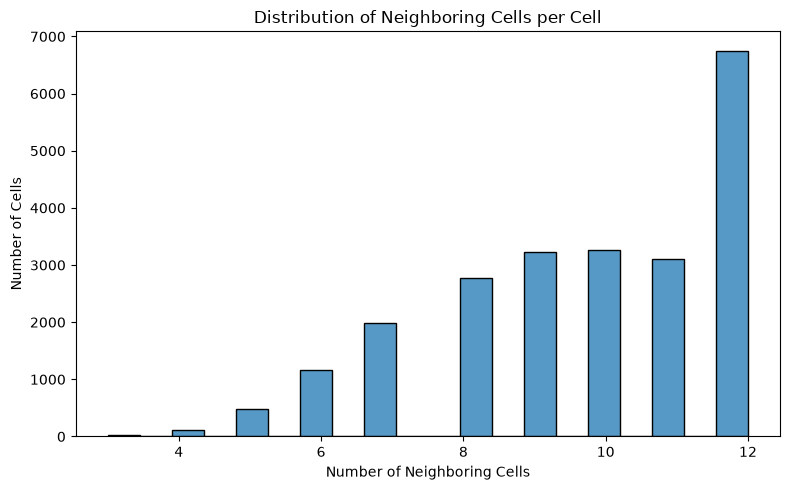

In [11]:
# Neighbor count and basic mapping coverage
if "Neighbor_Cell_ID" in df1.columns:
    def count_neighbors(value):
        if pd.isna(value) or str(value).strip() == "":
            return 0
        return len([x for x in str(value).split(",") if x.strip()])

    df1["Neighbor_Count"] = df1["Neighbor_Cell_ID"].apply(count_neighbors)
    print("Neighbor-count statistics:")
    display(df1["Neighbor_Count"].describe().to_frame("Neighbor_Count"))

    known_cells = set(df1["Cell_ID"].dropna().astype(str))
    neighbor_refs = set()
    for value in df1["Neighbor_Cell_ID"].dropna().astype(str):
        neighbor_refs.update(x.strip() for x in value.split(",") if x.strip())
    missing_neighbor_refs = neighbor_refs - known_cells
    print("Distinct neighbor IDs referenced:", len(neighbor_refs))
    print("Neighbor IDs not found in Dataset 1:", len(missing_neighbor_refs))

    plt.figure(figsize=(8, 5))
    sns.histplot(df1["Neighbor_Count"], bins=20)
    plt.title("Distribution of Neighboring Cells per Cell")
    plt.xlabel("Number of Neighboring Cells")
    plt.ylabel("Number of Cells")
    plt.tight_layout()
    plt.show()
else:
    print("Neighbor_Cell_ID column not present; neighbor-count EDA skipped.")



## 6.1 Data Ingestion — Dataset 2 File and Schema Validation

Dataset 2 is a very large merged CSV. Before performing EDA, the notebook checks its header and reads a small sample to confirm the schema.


In [12]:
# Read a bounded sample only; never load the entire large Dataset 2 here
sample_df2 = pd.read_csv(DATASET_2_MERGED_FILE, nrows=10_000, low_memory=False)
print("Dataset 2 sample shape:", sample_df2.shape)
display(sample_df2.head())
print("\nDataset 2 columns:")
print(sample_df2.columns.tolist())


Dataset 2 sample shape: (10000, 16)


,Timestamp,Site_ID,Cell_ID,Record_Type,Status,Traffic,Connected_Users,Throughput,Latency,Packet_Loss,Load,Capacity,Alarm_Count,Previous_Outage_Count,Cell_Down_Time,Cell_Up_Time
0,2024-01-01,UG-BUS-1658,UG-BUS-1658-S02,KPI,UP,2.129,23.0,1.306,64.562,0.320,20.428,34.391,0.0,0,NaN,NaN
1,2024-01-01,UG-MBA-5831,UG-MBA-5831-S04,KPI,UP,20.941,138.0,33.760,31.910,0.797,203.920,178.489,0.0,0,NaN,NaN
2,2024-01-01,UG-KIT-2854,UG-KIT-2854-S04,KPI,UP,24.122,80.0,79.612,41.128,1.047,331.371,307.217,0.0,0,NaN,NaN
3,2024-01-01,UG-ARU-5548,UG-ARU-5548-S03,KPI,UP,13.871,30.0,35.882,44.813,0.302,116.953,151.059,0.0,0,NaN,NaN
4,2024-01-01,UG-KLA-0402,UG-KLA-0402-S01,KPI,UP,0.475,25.0,0.210,139.754,0.871,8.629,18.711,0.0,0,NaN,NaN



Dataset 2 columns:
['Timestamp', 'Site_ID', 'Cell_ID', 'Record_Type', 'Status', 'Traffic', 'Connected_Users', 'Throughput', 'Latency', 'Packet_Loss', 'Load', 'Capacity', 'Alarm_Count', 'Previous_Outage_Count', 'Cell_Down_Time', 'Cell_Up_Time']


In [13]:
# Schema check: report expected, optional, and unexpected columns
expected_df2_cols = [
    "Timestamp", "Site_ID", "Cell_ID", "Record_Type", "Status",
    "Traffic", "Connected_Users", "Throughput", "Latency", "Packet_Loss",
    "Load", "Capacity", "Alarm_Count", "Previous_Outage_Count",
    "Cell_Down_Time", "Cell_Up_Time"
]
missing_expected = [c for c in expected_df2_cols if c not in sample_df2.columns]
unexpected = [c for c in sample_df2.columns if c not in expected_df2_cols]
print("Missing expected columns:", missing_expected)
print("Unexpected columns:", unexpected)
required_schema = ["Timestamp", "Site_ID", "Cell_ID", "Record_Type"]
missing_required_schema = [c for c in required_schema if c not in sample_df2.columns]
if missing_required_schema:
    raise ValueError(f"Essential Dataset 2 columns missing: {missing_required_schema}")
print("Essential schema check: PASS")


Missing expected columns: []
Unexpected columns: []
Essential schema check: PASS


## 6.2 Data Understanding and EDA — Dataset 2 Summary

Dataset 2 is scanned in chunks so the entire 133.9M-row CSV is not loaded into RAM. The scan summarizes record types, status, time range, unique IDs, missing values by record type, and bounded samples of KPI and event records. Distribution and relationship plots use the bounded KPI sample; these are exploratory summaries, not full-population estimates unless explicitly stated.

In [14]:
# 6.2 Dataset 2 EDA scan — summary, missingness, KPI sample, and events
# Chunked processing: do not load the full Dataset 2 into memory.

import pandas as pd
import numpy as np

CHUNK_SIZE = 50_000
PLOT_SAMPLE_SIZE = 100_000
SAMPLE_PER_CHUNK = 100  # bounded approximate sample for EDA plots

# Inspect header first so this cell tolerates optional columns.
dataset2_columns = pd.read_csv(DATASET_2_MERGED_FILE, nrows=0).columns.tolist()

identity_cols = [
    c for c in ["Timestamp", "Site_ID", "Cell_ID", "Record_Type", "Status"]
    if c in dataset2_columns
]
kpi_candidate_cols = [
    c for c in [
        "Traffic", "Connected_Users", "Throughput", "Latency",
        "Packet_Loss", "Load", "Capacity", "Alarm_Count",
        "Previous_Outage_Count"
    ] if c in dataset2_columns
]
event_candidate_cols = [
    c for c in ["Cell_Down_Time", "Cell_Up_Time"]
    if c in dataset2_columns
]
MISSING_CHECK_COLS = kpi_candidate_cols + event_candidate_cols
scan_cols = list(dict.fromkeys(identity_cols + MISSING_CHECK_COLS))

if not {"Timestamp", "Site_ID", "Cell_ID", "Record_Type"}.issubset(dataset2_columns):
    raise ValueError(
        "Dataset 2 must contain Timestamp, Site_ID, Cell_ID, and Record_Type."
    )

total_rows = 0
record_counts = {}
status_counts = {}
min_time, max_time = None, None

# Count missing values by Record_Type.
rows_by_type = {}
missing_by_type = {}

# Bounded sample of KPI rows for descriptive statistics and plots.
kpi_sample_parts = []

# Keep only OUTAGE/RECOVERY event rows for event-level EDA.
event_parts = []

# Exact unique IDs are manageable for this project, unlike all KPI rows.
unique_sites = set()
unique_cells = set()

for chunk in pd.read_csv(
    DATASET_2_MERGED_FILE,
    usecols=scan_cols,
    chunksize=CHUNK_SIZE,
    dtype={
        c: "string" for c in
        ["Timestamp", "Site_ID", "Cell_ID", "Record_Type", "Status"]
        if c in scan_cols
    },
    on_bad_lines="error",
    low_memory=False
):
    total_rows += len(chunk)

    # Normalize event/category labels for counting and filtering.
    record_type = chunk["Record_Type"].fillna("UNKNOWN").astype("string").str.upper()
    status = (
        chunk["Status"].fillna("UNKNOWN").astype("string")
        if "Status" in chunk.columns
        else pd.Series("UNKNOWN", index=chunk.index, dtype="string")
    )

    for key, value in record_type.value_counts(dropna=False).items():
        record_counts[str(key)] = record_counts.get(str(key), 0) + int(value)

    for key, value in status.value_counts(dropna=False).items():
        status_counts[str(key)] = status_counts.get(str(key), 0) + int(value)

    # Timestamp range
    times = pd.to_datetime(chunk["Timestamp"], errors="coerce")
    valid_times = times.dropna()
    if not valid_times.empty:
        lo, hi = valid_times.min(), valid_times.max()
        min_time = lo if min_time is None else min(min_time, lo)
        max_time = hi if max_time is None else max(max_time, hi)

    unique_sites.update(chunk["Site_ID"].dropna().astype(str).unique())
    unique_cells.update(chunk["Cell_ID"].dropna().astype(str).unique())

    # Missing values by record type, so expected event-row blanks are not
    # confused with missing KPI measurements.
    for rt in record_type.unique():
        mask = record_type.eq(rt)
        rows_by_type[str(rt)] = rows_by_type.get(str(rt), 0) + int(mask.sum())
        if str(rt) not in missing_by_type:
            missing_by_type[str(rt)] = {col: 0 for col in MISSING_CHECK_COLS}
        for col in MISSING_CHECK_COLS:
            if col in chunk.columns:
                missing_by_type[str(rt)][col] += int(chunk.loc[mask, col].isna().sum())

    # Random bounded sample of regular KPI rows.
    kpi_chunk = chunk.loc[record_type.eq("KPI")].copy()
    if not kpi_chunk.empty:
        for col in kpi_candidate_cols:
            kpi_chunk[col] = pd.to_numeric(kpi_chunk[col], errors="coerce")
        take = min(SAMPLE_PER_CHUNK, len(kpi_chunk))
        kpi_sample_parts.append(
            kpi_chunk.sample(n=take, random_state=42)
        )

    # Keep event records only; these are much fewer than KPI observations.
    event_mask = record_type.isin(["OUTAGE", "RECOVERY"])
    if event_mask.any():
        event_parts.append(chunk.loc[event_mask].copy())

print(f"Total rows: {total_rows:,}")
print(f"Unique sites: {len(unique_sites):,}")
print(f"Unique cells: {len(unique_cells):,}")
print(f"Time range: {min_time} to {max_time}")

print("\nRecord types:")
display(
    pd.Series(record_counts, name="Count")
    .sort_values(ascending=False).to_frame()
)

print("\nStatus:")
display(
    pd.Series(status_counts, name="Count")
    .sort_values(ascending=False).to_frame()
)

# Variables expected by later EDA cells.
missing_rows = []
for rt, row_count in rows_by_type.items():
    record = {"Record_Type": rt, "Rows": row_count}
    record.update(missing_by_type.get(rt, {}))
    missing_rows.append(record)
missing_summary = pd.DataFrame(missing_rows)

# Combine per-chunk samples and cap the final plotting sample.
if kpi_sample_parts:
    kpi_sample_df = pd.concat(kpi_sample_parts, ignore_index=True)
    if len(kpi_sample_df) > PLOT_SAMPLE_SIZE:
        kpi_sample_df = kpi_sample_df.sample(
            n=PLOT_SAMPLE_SIZE, random_state=42
        )
    kpi_sample_rows = kpi_sample_df.to_dict("records")
else:
    kpi_sample_rows = []

# Combine event rows for event-level analysis.
if event_parts:
    events_df = pd.concat(event_parts, ignore_index=True)
else:
    events_df = pd.DataFrame(columns=scan_cols)

for col in ["Timestamp", "Cell_Down_Time", "Cell_Up_Time"]:
    if col in events_df.columns:
        events_df[col] = pd.to_datetime(events_df[col], format="ISO8601", errors="coerce")

if "Record_Type" in events_df.columns:
    events_df["Record_Type"] = (
        events_df["Record_Type"].astype("string").str.upper()
    )

print("\nMissing-value counts by Record_Type:")
display(missing_summary)

print("\nKPI EDA sample rows:", f"{len(kpi_sample_rows):,}")
print("OUTAGE/RECOVERY event rows retained:", f"{len(events_df):,}")

Total rows: 133,951,489
Unique sites: 6,000
Unique cells: 22,900
Time range: 2024-01-01 00:00:00 to 2025-12-31 23:57:29

Record types:


,Count
KPI,133899778
OUTAGE,25859
RECOVERY,25852



Status:


,Count
UP,133925630
DOWN,25859



Missing-value counts by Record_Type:


,Record_Type,Rows,Traffic,Connected_Users,Throughput,Latency,Packet_Loss,Load,Capacity,Alarm_Count,Previous_Outage_Count,Cell_Down_Time,Cell_Up_Time
0,KPI,133899778,0,0,0,0,0,0,0,0,0,133899778,133899778
1,OUTAGE,25859,25859,25859,25859,25859,25859,25859,25859,25859,0,0,25859
2,RECOVERY,25852,25852,25852,25852,25852,25852,25852,25852,25852,0,0,0



KPI EDA sample rows: 100,000
OUTAGE/RECOVERY event rows retained: 51,711



## 6.2 Data Understanding and EDA — Missing-Value Analysis

### Important interpretation
A `NaN` in an `OUTAGE` or `RECOVERY` event row can be **expected** because that row records an event rather than a regular KPI measurement.

Therefore, missing values are analyzed **by `Record_Type`**. This helps distinguish expected event-row missingness from missing KPI values in normal `KPI` records.


In [15]:
# Missing-value rate for regular KPI records only

kpi_summary = missing_summary[
    missing_summary["Record_Type"] == "KPI"
].copy()

if not kpi_summary.empty:
    kpi_rows = int(kpi_summary["Rows"].iloc[0])

    rates = []

    for col in MISSING_CHECK_COLS:
        count = int(kpi_summary[col].iloc[0])

        rates.append({
            "Variable": col,
            "Missing_Count": count,
            "Missing_Percent": round(
                count / kpi_rows * 100,
                2
            ) if kpi_rows else 0
        })

    kpi_missing_df = pd.DataFrame(rates)

    display(
        kpi_missing_df.sort_values(
            "Missing_Percent",
            ascending=False
        )
    )
else:
    print("No regular KPI records found.")


,Variable,Missing_Count,Missing_Percent
9,Cell_Down_Time,133899778,100.0
10,Cell_Up_Time,133899778,100.0
0,Traffic,0,0.0
2,Throughput,0,0.0
1,Connected_Users,0,0.0
3,Latency,0,0.0
4,Packet_Loss,0,0.0
6,Capacity,0,0.0
5,Load,0,0.0
8,Previous_Outage_Count,0,0.0



## 6.2 Data Understanding and EDA — KPI Sample for Visualization

Only regular `KPI` records are sampled for distribution and relationship plots. This keeps the plots meaningful and avoids treating event-row `NaN` values as KPI distributions.


In [16]:
# Convert the bounded KPI reservoir sample to a DataFrame
kpi_sample = pd.DataFrame(kpi_sample_rows)

numeric_candidates = [
    "Traffic", "Connected_Users", "Throughput", "Latency", "Packet_Loss",
    "Load", "Capacity", "Alarm_Count", "Previous_Outage_Count"
]
for col in numeric_candidates:
    if col in kpi_sample.columns:
        kpi_sample[col] = pd.to_numeric(kpi_sample[col], errors="coerce")

print("KPI sample shape:", kpi_sample.shape)
display(kpi_sample.head())

# Basic sample-based quality checks; these flag values for review, not automatic deletion.
if not kpi_sample.empty:
    print("Duplicate (Timestamp, Site_ID, Cell_ID) keys in KPI sample:",
          int(kpi_sample.duplicated([c for c in ["Timestamp", "Site_ID", "Cell_ID"] if c in kpi_sample.columns]).sum())
          if all(c in kpi_sample.columns for c in ["Timestamp", "Site_ID", "Cell_ID"]) else "Not available")
    nonnegative_candidates = [c for c in ["Traffic", "Connected_Users", "Latency", "Packet_Loss", "Load", "Capacity", "Alarm_Count", "Previous_Outage_Count"] if c in kpi_sample.columns]
    for col in nonnegative_candidates:
        values = kpi_sample[col].dropna()
        print(f"{col}: negative values in sample = {int((values < 0).sum()):,}")


KPI sample shape: (100000, 16)


,Timestamp,Site_ID,Cell_ID,Record_Type,Status,Traffic,Connected_Users,Throughput,Latency,Packet_Loss,Load,Capacity,Alarm_Count,Previous_Outage_Count,Cell_Down_Time,Cell_Up_Time
0,2024-08-26 06:00:00,UG-WAK-5411,UG-WAK-5411-S03,KPI,UP,18.621,124.0,9.945,35.757,0.893,150.284,138.179,0.0,1,NaN,NaN
1,2024-08-01 03:00:00,UG-MSK-0800,UG-MSK-0800-S03,KPI,UP,15.137,109.0,8.325,50.916,0.506,112.324,112.017,0.0,0,NaN,NaN
2,2025-12-02 06:00:00,UG-KAB-3693,UG-KAB-3693-S02,KPI,UP,5.416,41.0,3.783,66.918,0.834,24.878,40.159,0.0,1,NaN,NaN
3,2024-10-01 03:00:00,UG-TOR-2586,UG-TOR-2586-S01,KPI,UP,0.825,37.0,0.206,130.585,0.217,10.164,19.158,0.0,1,NaN,NaN
4,2024-03-26 21:00:00,UG-IGA-3731,UG-IGA-3731-S01,KPI,UP,3.694,102.0,0.183,154.254,1.416,15.261,18.331,0.0,0,NaN,NaN


Duplicate (Timestamp, Site_ID, Cell_ID) keys in KPI sample: 0
Traffic: negative values in sample = 0
Connected_Users: negative values in sample = 0
Latency: negative values in sample = 0
Packet_Loss: negative values in sample = 0
Load: negative values in sample = 0
Capacity: negative values in sample = 0
Alarm_Count: negative values in sample = 0
Previous_Outage_Count: negative values in sample = 0


### Additional EDA check — KPI value quality and plausibility

These checks use the bounded KPI sample, not all ~134M rows. They flag impossible or unusual values for review; they do not automatically remove records. Interpret limits according to the dataset's units and schema.

In [17]:
# Additional EDA quality checks on the bounded KPI sample
# Sample-level checks only; do not treat these as full-dataset counts.

range_rules = {
    "Traffic": (0, None),
    "Connected_Users": (0, None),
    "Throughput": (0, None),
    "Latency": (0, None),
    "Packet_Loss": (0, 100),
    "Load": (0, None),
    "Capacity": (0, None),
    "Alarm_Count": (0, None),
    "Previous_Outage_Count": (0, None),
}

quality_rows = []
for col, (lower, upper) in range_rules.items():
    if col not in kpi_sample.columns:
        continue

    values = pd.to_numeric(kpi_sample[col], errors="coerce")
    finite = values.replace([np.inf, -np.inf], np.nan).dropna()

    row = {
        "Variable": col,
        "Sample_Rows": int(len(values)),
        "Missing_or_Nonnumeric": int(values.isna().sum()),
        "Negative_Count": int((finite < 0).sum()),
        "Above_100_Count": int((finite > 100).sum()) if col == "Packet_Loss" else None,
        "Minimum": finite.min() if not finite.empty else np.nan,
        "Maximum": finite.max() if not finite.empty else np.nan,
    }

    if lower is not None:
        row["Below_Lower_Bound"] = int((finite < lower).sum())
    if upper is not None:
        row["Above_Upper_Bound"] = int((finite > upper).sum())

    quality_rows.append(row)

kpi_quality_check = pd.DataFrame(quality_rows)
display(kpi_quality_check)

print(
    "Interpretation: these are sample-level flags. Confirm units and "
    "dataset-generation rules before deciding whether any value is invalid."
)


,Variable,Sample_Rows,Missing_or_Nonnumeric,Negative_Count,Above_100_Count,Minimum,Maximum,Below_Lower_Bound,Above_Upper_Bound
0,Traffic,100000,0,0,NaN,0.208,124.015,0,NaN
1,Connected_Users,100000,0,0,NaN,9.000,540.000,0,NaN
2,Throughput,100000,0,0,NaN,0.049,284.904,0,NaN
3,Latency,100000,0,0,NaN,7.829,413.765,0,NaN
4,Packet_Loss,100000,0,0,0.0,0.023,3.847,0,0.0
5,Load,100000,0,0,NaN,4.745,1588.435,0,NaN
6,Capacity,100000,0,0,NaN,12.001,399.992,0,NaN
7,Alarm_Count,100000,0,0,NaN,0.000,5.000,0,NaN
8,Previous_Outage_Count,100000,0,0,NaN,0.000,7.000,0,NaN


Interpretation: these are sample-level flags. Confirm units and dataset-generation rules before deciding whether any value is invalid.


In [18]:
# Numeric KPI descriptive statistics on the bounded sample
numeric_kpis = [
    c for c in [
        "Traffic", "Connected_Users", "Throughput", "Latency", "Packet_Loss",
        "Load", "Capacity", "Alarm_Count", "Previous_Outage_Count"
    ] if c in kpi_sample.columns
]
if numeric_kpis and not kpi_sample.empty:
    display(kpi_sample[numeric_kpis].describe().T)
else:
    print("No numeric KPI columns are available for descriptive statistics.")


,count,mean,std,min,25%,50%,75%,max
Traffic,100000.0,13.966777,17.453308,0.208,2.21200,6.3055,19.79950,124.015
Connected_Users,100000.0,109.608890,83.344943,9.000,49.00000,83.0000,143.00000,540.000
Throughput,100000.0,21.844381,30.485994,0.049,0.78000,4.5270,34.18625,284.904
Latency,100000.0,80.208917,35.763495,7.829,52.54800,77.0765,102.42025,413.765
Packet_Loss,100000.0,1.017803,0.620474,0.023,0.53900,0.8900,1.36700,3.847
Load,100000.0,152.953059,203.829139,4.745,16.06375,50.5045,198.81000,1588.435
Capacity,100000.0,110.864588,102.093824,12.001,24.43000,66.6100,161.67100,399.992
Alarm_Count,100000.0,0.024760,0.218923,0.000,0.00000,0.0000,0.00000,5.000
Previous_Outage_Count,100000.0,0.558280,0.817478,0.000,0.00000,0.0000,1.00000,7.000


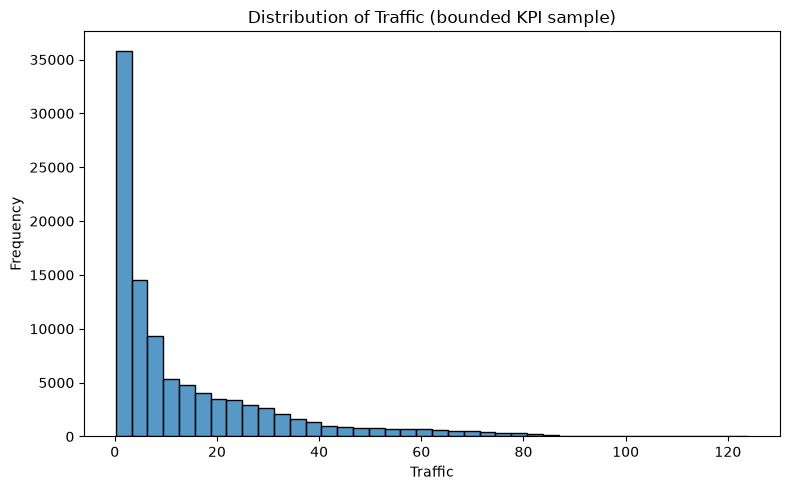

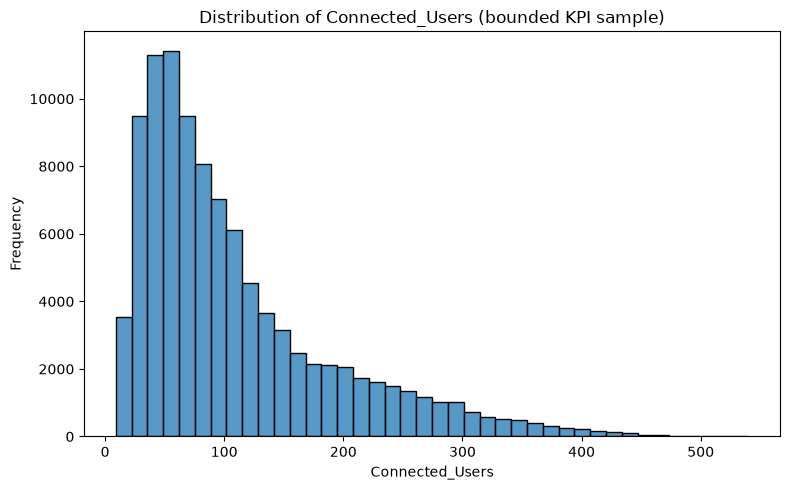

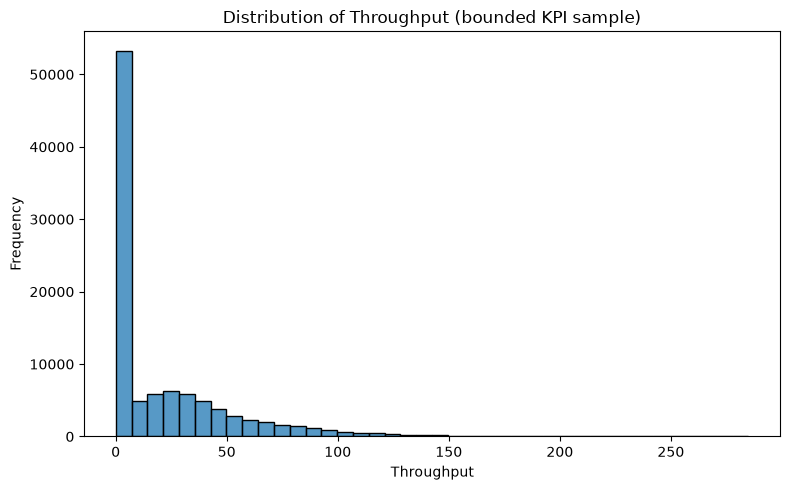

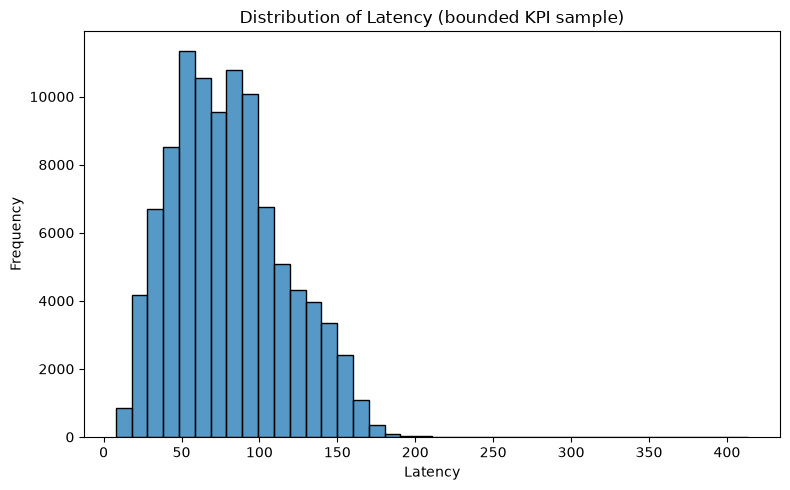

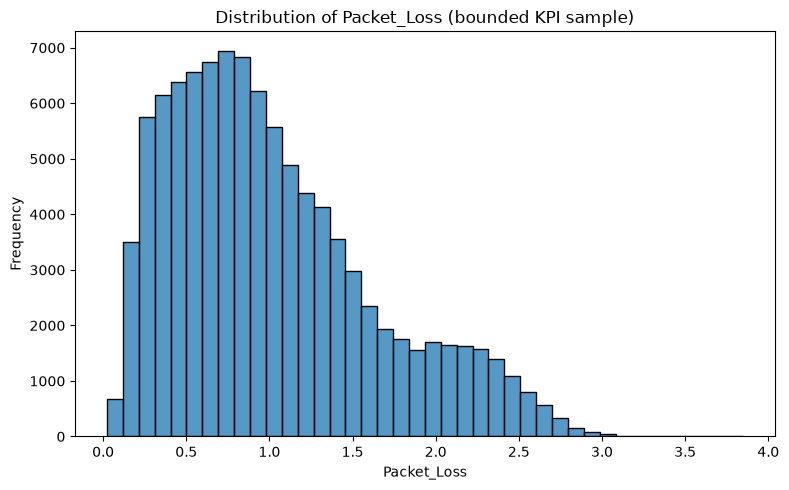

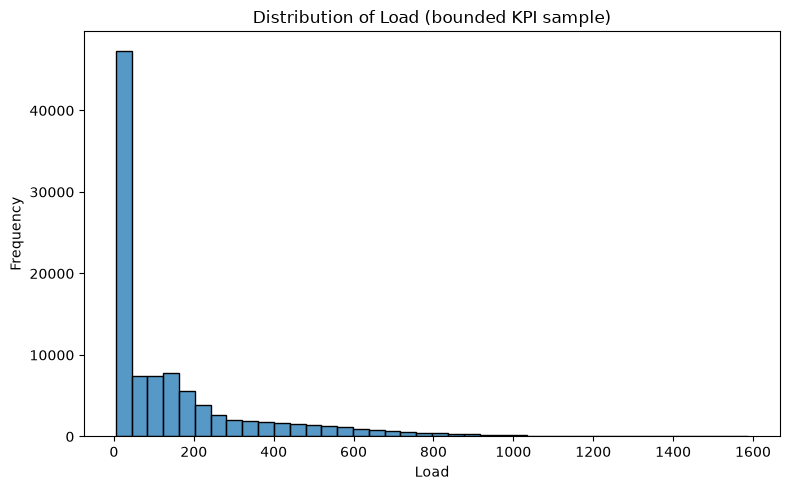

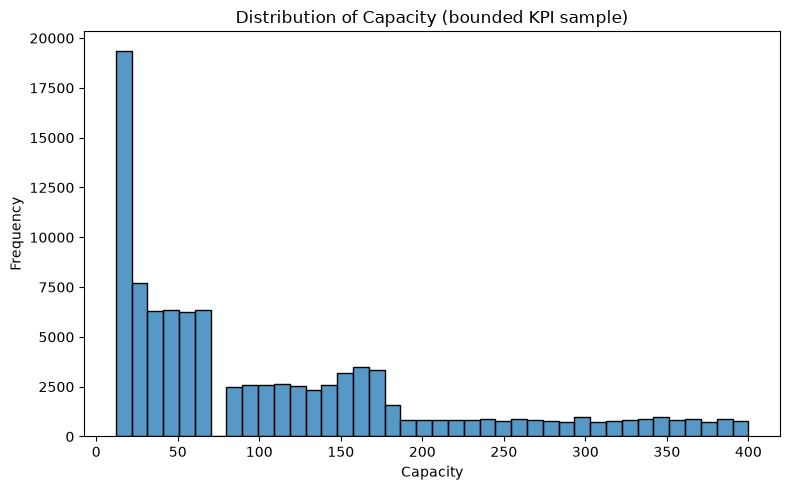

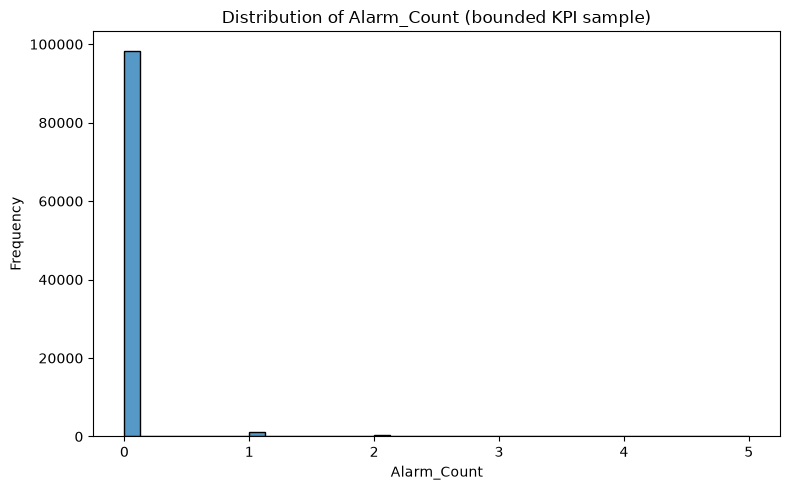

In [19]:
# Distribution plots for available numeric KPI columns
plot_cols = [c for c in [
    "Traffic", "Connected_Users", "Throughput", "Latency", "Packet_Loss",
    "Load", "Capacity", "Alarm_Count"
] if c in kpi_sample.columns]

for col in plot_cols:
    values = kpi_sample[col].dropna()
    if values.empty:
        continue
    plt.figure(figsize=(8, 5))
    sns.histplot(values, bins=40)
    plt.title(f"Distribution of {col} (bounded KPI sample)")
    plt.xlabel(col)
    plt.ylabel("Frequency")
    plt.tight_layout()
    plt.show()


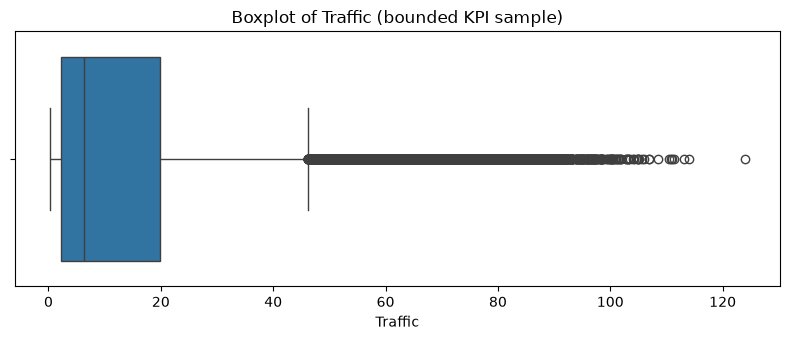

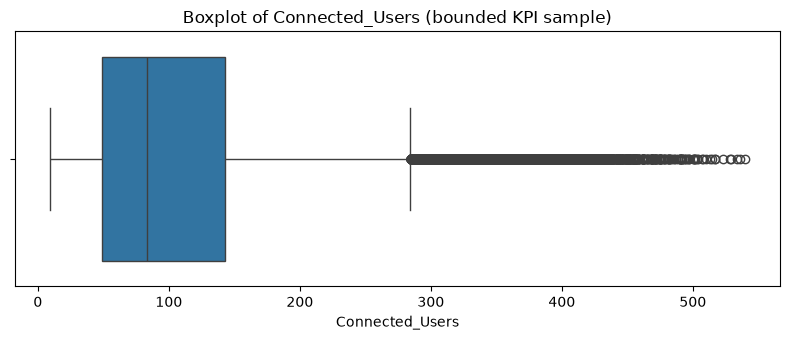

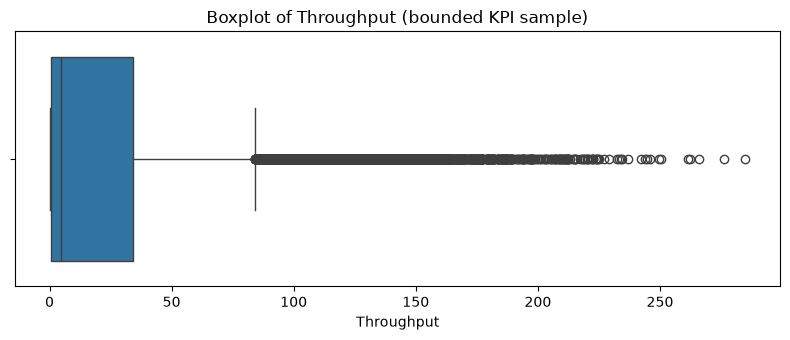

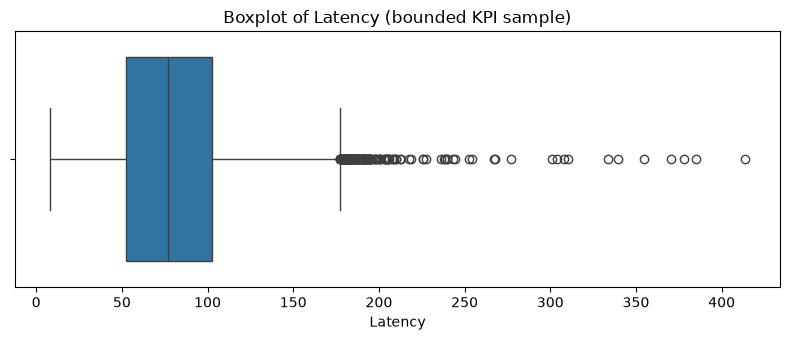

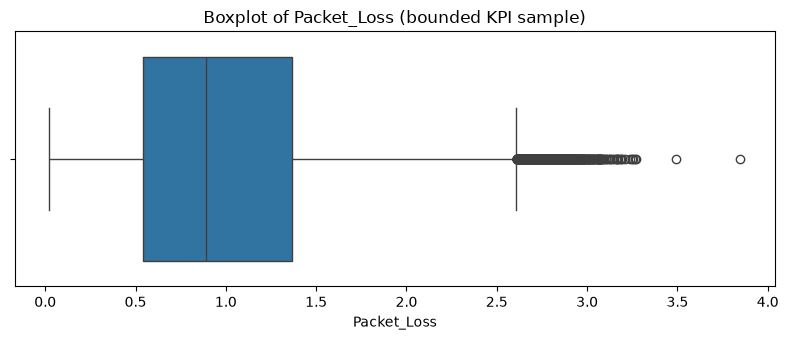

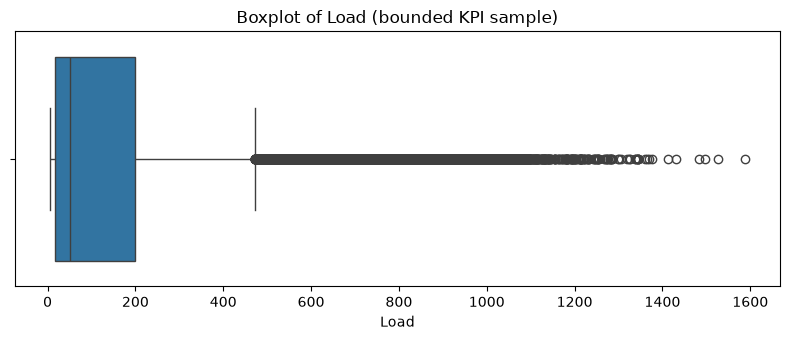

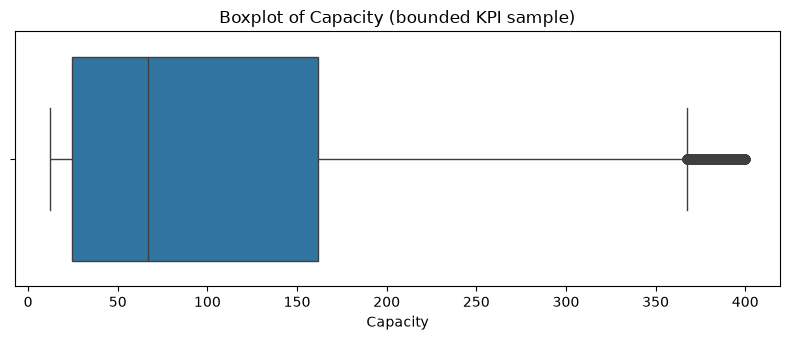

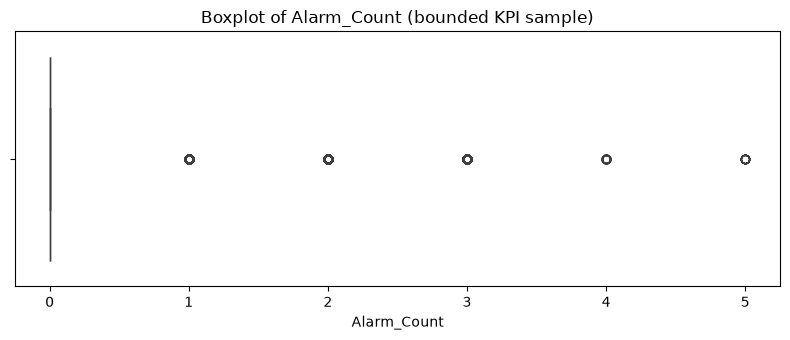

In [20]:
# Boxplots for visual outlier inspection (sample only)
for col in plot_cols:
    values = kpi_sample[col].dropna()
    if values.empty:
        continue
    plt.figure(figsize=(8, 3.5))
    sns.boxplot(x=values)
    plt.title(f"Boxplot of {col} (bounded KPI sample)")
    plt.xlabel(col)
    plt.tight_layout()
    plt.show()


## 6.2 Data Understanding and EDA — Outlier Summary Using IQR

Boxplots provide a visual check. The table below also counts observations outside the standard IQR fences (Q1 − 1.5×IQR and Q3 + 1.5×IQR). Potential outliers are inspected rather than automatically deleted.

In [21]:
# IQR-based outlier counts on the bounded KPI sample
outlier_rows = []
for col in numeric_kpis:
    series = kpi_sample[col].dropna()
    if series.empty:
        continue
    q1, q3 = series.quantile(0.25), series.quantile(0.75)
    iqr = q3 - q1
    lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    outlier_count = int(((series < lower) | (series > upper)).sum())
    outlier_rows.append({
        "Variable": col, "Q1": q1, "Q3": q3, "IQR": iqr,
        "Lower_Fence": lower, "Upper_Fence": upper,
        "Outlier_Count": outlier_count,
        "Outlier_Percent": round(outlier_count / len(series) * 100, 2)
    })

iqr_outlier_table = pd.DataFrame(outlier_rows)
display(iqr_outlier_table)
print("IQR outliers are candidates for review, not automatic errors.")


,Variable,Q1,Q3,IQR,Lower_Fence,Upper_Fence,Outlier_Count,Outlier_Percent
0,Traffic,2.21200,19.79950,17.58750,-24.169250,46.180750,6958,6.96
1,Connected_Users,49.00000,143.00000,94.00000,-92.000000,284.000000,5241,5.24
2,Throughput,0.78000,34.18625,33.40625,-49.329375,84.295625,5251,5.25
3,Latency,52.54800,102.42025,49.87225,-22.260375,177.228625,207,0.21
4,Packet_Loss,0.53900,1.36700,0.82800,-0.703000,2.609000,1169,1.17
5,Load,16.06375,198.81000,182.74625,-258.055625,472.929375,9383,9.38
6,Capacity,24.43000,161.67100,137.24100,-181.431500,367.532500,2714,2.71
7,Alarm_Count,0.00000,0.00000,0.00000,0.000000,0.000000,1642,1.64
8,Previous_Outage_Count,0.00000,1.00000,1.00000,-1.500000,2.500000,3091,3.09


IQR outliers are candidates for review, not automatic errors.


## 6.2 Data Understanding and EDA — Distribution and Skewness

In [22]:
# Skewness summary on the bounded sample
if numeric_kpis:
    skewness = kpi_sample[numeric_kpis].skew(numeric_only=True).sort_values(ascending=False)
    skewness_table = skewness.to_frame("Skewness")
    skewness_table["Interpretation"] = np.select(
        [skewness.abs() < 0.5, skewness.abs() < 1.0],
        ["Approximately symmetric", "Moderately skewed"],
        default="Highly skewed"
    )
    display(skewness_table)
else:
    print("No numeric KPI columns available for skewness analysis.")


,Skewness,Interpretation
Alarm_Count,11.368995,Highly skewed
Load,2.004302,Highly skewed
Throughput,1.996062,Highly skewed
Traffic,1.947890,Highly skewed
Previous_Outage_Count,1.618480,Highly skewed
Connected_Users,1.451313,Highly skewed
Capacity,1.160164,Highly skewed
Packet_Loss,0.809885,Moderately skewed
Latency,0.492560,Approximately symmetric


## 6.2 Data Understanding and EDA — KPI Relationships

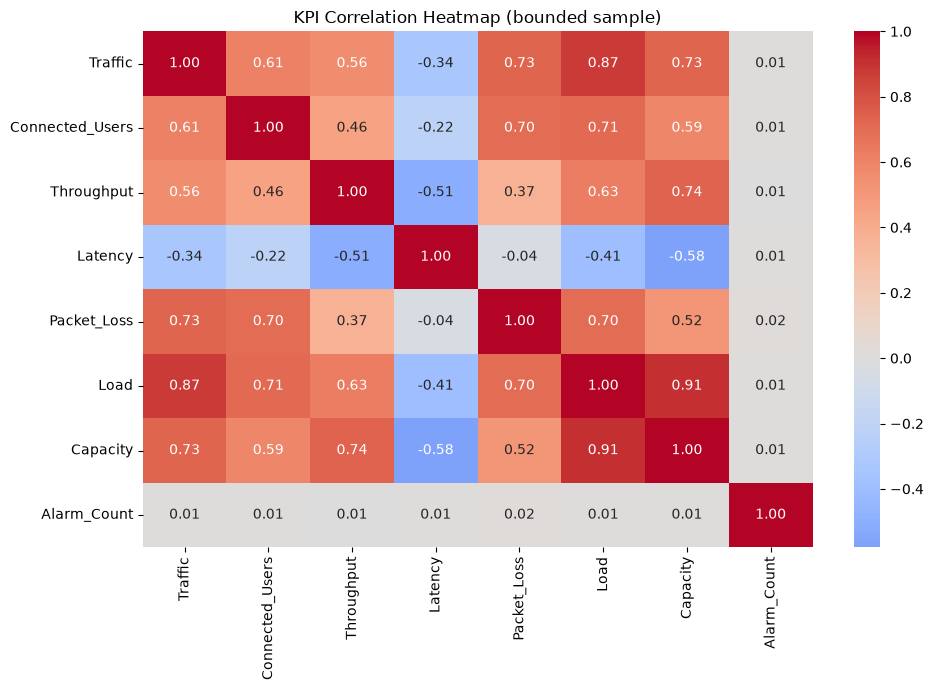

In [23]:
# Correlation heatmap on the bounded KPI sample
corr_cols = [c for c in [
    "Traffic", "Connected_Users", "Throughput", "Latency", "Packet_Loss",
    "Load", "Capacity", "Alarm_Count"
] if c in kpi_sample.columns]
if len(corr_cols) >= 2:
    corr = kpi_sample[corr_cols].corr(numeric_only=True)
    plt.figure(figsize=(10, 7))
    sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0)
    plt.title("KPI Correlation Heatmap (bounded sample)")
    plt.tight_layout()
    plt.show()
else:
    print("At least two numeric KPI columns are needed for a correlation heatmap.")


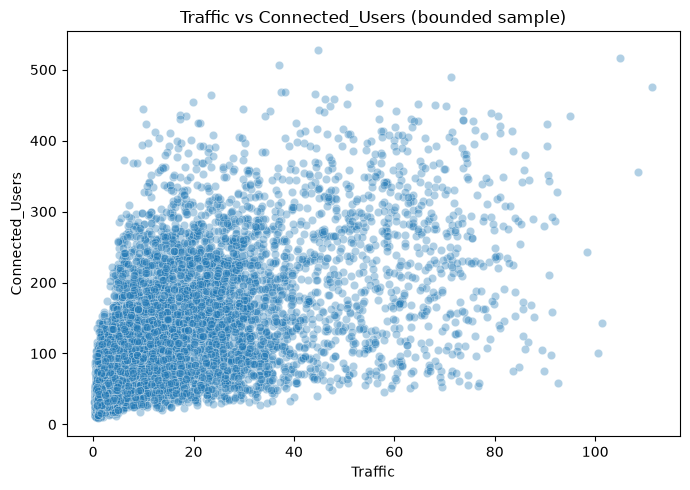

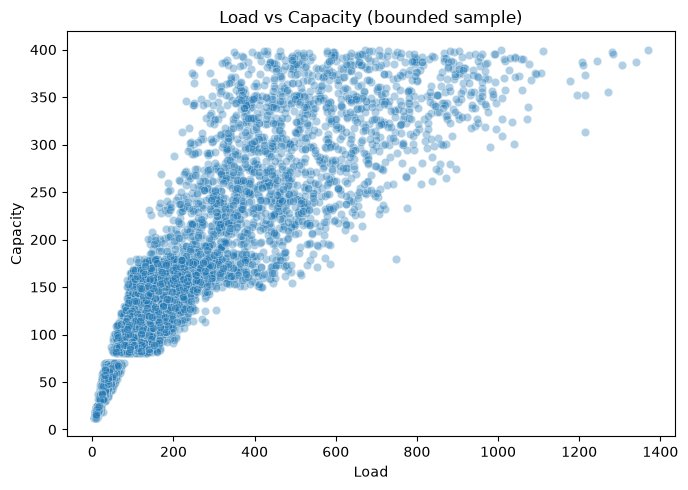

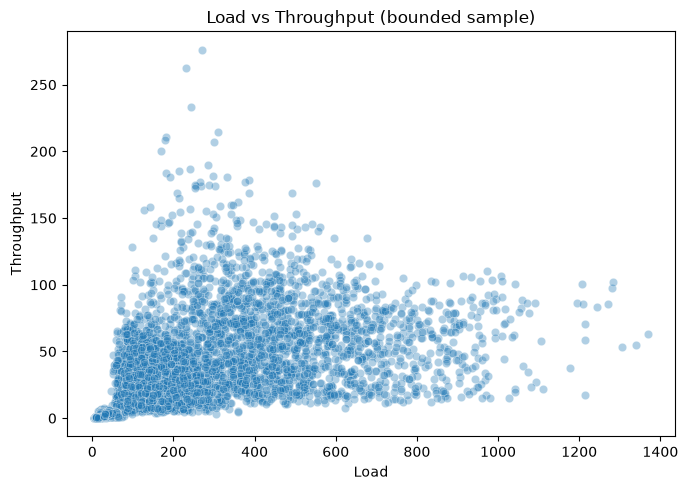

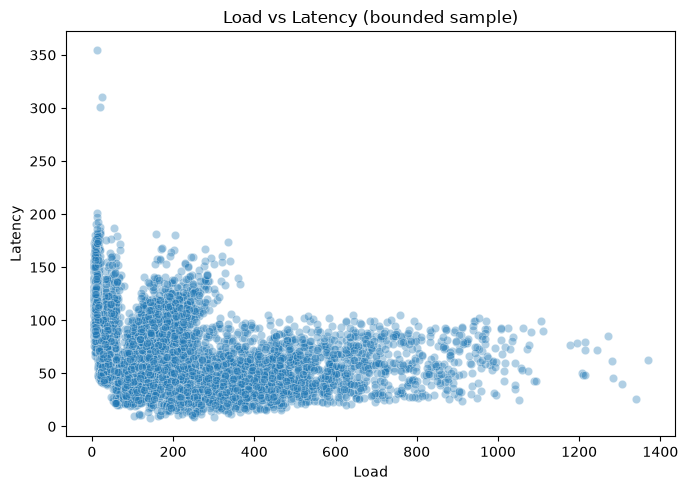

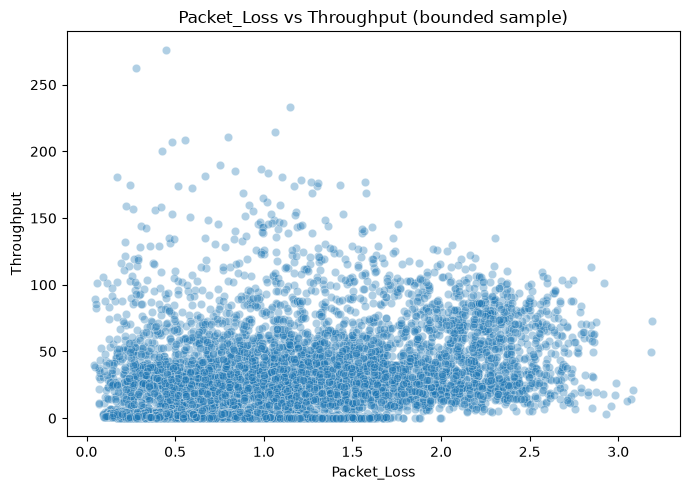

In [24]:
# Selected KPI relationship plots; relationships are descriptive, not causal proof
relationships = [
    ("Traffic", "Connected_Users"),
    ("Load", "Capacity"),
    ("Load", "Throughput"),
    ("Load", "Latency"),
    ("Packet_Loss", "Throughput")
]
for x_col, y_col in relationships:
    if x_col not in kpi_sample.columns or y_col not in kpi_sample.columns:
        continue
    plot_df = kpi_sample[[x_col, y_col]].dropna()
    if plot_df.empty:
        continue
    plot_df = plot_df.sample(n=min(10_000, len(plot_df)), random_state=42)
    plt.figure(figsize=(7, 5))
    sns.scatterplot(data=plot_df, x=x_col, y=y_col, alpha=0.35)
    plt.title(f"{x_col} vs {y_col} (bounded sample)")
    plt.tight_layout()
    plt.show()


## 6.2 Data Understanding and EDA — Derived Utilization

Utilization is calculated here for exploratory analysis only. The modelling feature is created again in Section 6.4 from the cleaned KPI file.

$$\text{Utilization (\%)} = \frac{\text{Load}}{\text{Capacity}} \times 100$$

,Utilization
count,100000.000000
mean,100.851551
std,54.465375
min,34.672059
25%,61.412351
50%,79.802099
75%,126.419695
max,425.407274


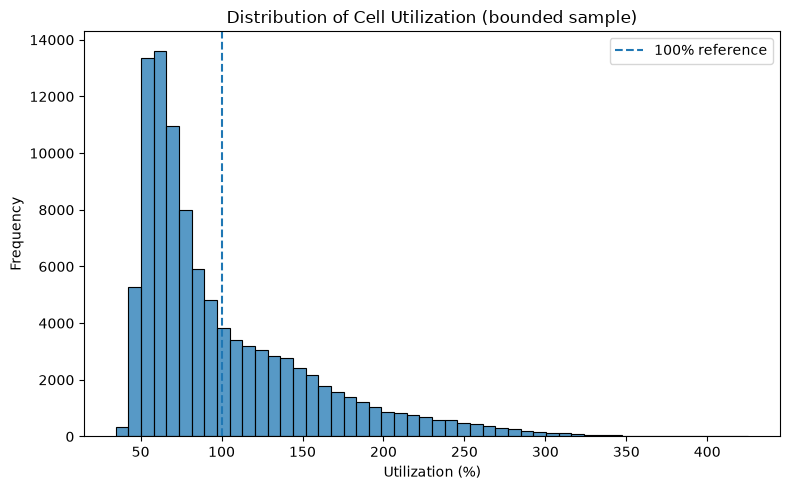

In [25]:
# Utilization distribution in the bounded KPI sample
if {"Load", "Capacity"}.issubset(kpi_sample.columns):
    capacity = pd.to_numeric(kpi_sample["Capacity"], errors="coerce")
    load = pd.to_numeric(kpi_sample["Load"], errors="coerce")
    kpi_sample["Utilization"] = (load / capacity.where(capacity > 0)) * 100
    utilization_clean = kpi_sample["Utilization"].replace([np.inf, -np.inf], np.nan).dropna()
    display(utilization_clean.describe().to_frame("Utilization"))
    if not utilization_clean.empty:
        plt.figure(figsize=(8, 5))
        sns.histplot(utilization_clean, bins=50)
        plt.axvline(100, linestyle="--", label="100% reference")
        plt.title("Distribution of Cell Utilization (bounded sample)")
        plt.xlabel("Utilization (%)")
        plt.ylabel("Frequency")
        plt.legend()
        plt.tight_layout()
        plt.show()
else:
    utilization_clean = pd.Series(dtype=float)
    print("Load or Capacity is unavailable; utilization EDA skipped.")


In [26]:
# Percentage of sampled KPI rows above 100% utilization
if len(utilization_clean):
    over_100 = (utilization_clean > 100).mean() * 100
    print(f"Sampled KPI rows with Utilization > 100%: {over_100:.2f}%")
    print("Values above 100% should be reviewed against the units and capacity definition.")
else:
    print("No valid utilization observations available.")


Sampled KPI rows with Utilization > 100%: 36.29%
Values above 100% should be reviewed against the units and capacity definition.



## 6.2 Data Understanding and EDA — Outage and Recovery Events

`OUTAGE` and `RECOVERY` are treated as event records. We load only these event records for event-level analysis.


In [27]:
# Event-level EDA dataset
# Reuse events_df created during the fast Dataset 2 scan above.

events_df = events_df.copy()

print("Event rows:", f"{len(events_df):,}")
print("Record types:")
display(
    events_df["Record_Type"]
    .value_counts(dropna=False)
    .to_frame("Count")
)

display(events_df.head())


Event rows: 51,711
Record types:


,Count
Record_Type,
OUTAGE,25859
RECOVERY,25852


,Timestamp,Site_ID,Cell_ID,Record_Type,Status,Traffic,Connected_Users,Throughput,Latency,Packet_Loss,Load,Capacity,Alarm_Count,Previous_Outage_Count,Cell_Down_Time,Cell_Up_Time
0,2024-01-01 01:24:03,UG-LIR-5980,UG-LIR-5980-S01,OUTAGE,DOWN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0,2024-01-01 01:24:03,NaT
1,2024-01-01 01:42:48,UG-JIN-2889,UG-JIN-2889-S01,OUTAGE,DOWN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0,2024-01-01 01:42:48,NaT
2,2024-01-01 01:56:43,UG-KML-4845,UG-KML-4845-S03,OUTAGE,DOWN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0,2024-01-01 01:56:43,NaT
3,2024-01-01 02:53:01,UG-BUG-0719,UG-BUG-0719-S03,OUTAGE,DOWN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0,2024-01-01 02:53:01,NaT
4,2024-01-01 03:03:17,UG-MSK-4922,UG-MSK-4922-S04,OUTAGE,DOWN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0,2024-01-01 03:03:17,NaT


In [28]:

# Event counts
display(
    events_df["Record_Type"]
    .value_counts()
    .to_frame("Count")
)


,Count
Record_Type,
OUTAGE,25859
RECOVERY,25852


Total OUTAGE events: 25,859


,Outage_Count
Month,
2024-01,1071
2024-02,984
2024-03,1087
2024-04,1019
2024-05,1000
2024-06,1085
2024-07,1092
2024-08,1131
2024-09,1183


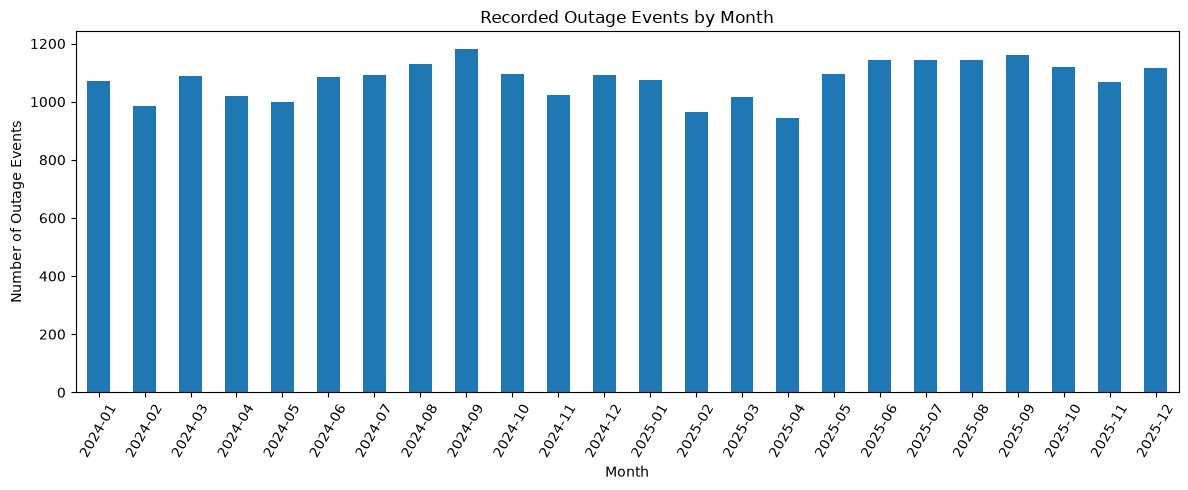

In [29]:

# Outage events only
outages = events_df[
    events_df["Record_Type"] == "OUTAGE"
].copy()

print("Total OUTAGE events:", f"{len(outages):,}")

# Outages per month
outages["Month"] = (
    outages["Cell_Down_Time"]
    .dt.to_period("M")
    .astype(str)
)

monthly_outages = (
    outages["Month"]
    .value_counts()
    .sort_index()
)

display(monthly_outages.to_frame("Outage_Count"))

plt.figure(figsize=(12, 5))
monthly_outages.plot(kind="bar")
plt.title("Recorded Outage Events by Month")
plt.xlabel("Month")
plt.ylabel("Number of Outage Events")
plt.xticks(rotation=60)
plt.tight_layout()
plt.show()



## 6.2 Data Understanding and EDA — Technology and Geography

Dataset 1 provides the technology and geographic context for Dataset 2 event records through `Site_ID + Cell_ID`.


In [30]:

# Add Dataset 1 context to outage events
outage_with_context = outages.merge(
    df1[
        [
            "Site_ID",
            "Cell_ID",
            "Technology",
            "Region",
            "District"
        ]
    ],
    on=["Site_ID", "Cell_ID"],
    how="left",
    validate="many_to_one"
)

print("Outage rows after context join:", len(outage_with_context))

print("\nOutages by technology:")
display(
    outage_with_context["Technology"]
    .value_counts(dropna=False)
    .to_frame("Count")
)

print("\nOutages by region:")
display(
    outage_with_context["Region"]
    .value_counts(dropna=False)
    .head(30)
    .to_frame("Count")
)

print("\nOutages by district:")
display(
    outage_with_context["District"]
    .value_counts(dropna=False)
    .head(30)
    .to_frame("Count")
)


Outage rows after context join: 25859

Outages by technology:


,Count
Technology,
2G,7264
3G,6800
4G,6764
5G,5031



Outages by region:


,Count
Region,
Eastern,7369
Western,6581
Northern,6466
Central,5443



Outages by district:


,Count
District,
Kabale,964
Yumbe,964
Fort Portal,962
Hoima,961
Mukono,956
Masaka,951
Kamuli,949
Iganga,948
Kasese,947


In [31]:

# Cells and sites with the highest number of recorded outages

outages_by_cell = (
    outage_with_context
    .groupby("Cell_ID")
    .size()
    .sort_values(ascending=False)
)

outages_by_site = (
    outage_with_context
    .groupby("Site_ID")
    .size()
    .sort_values(ascending=False)
)

print("Top cells by outage count:")
display(outages_by_cell.head(20).to_frame("Outage_Count"))

print("Top sites by outage count:")
display(outages_by_site.head(20).to_frame("Outage_Count"))


Top cells by outage count:


,Outage_Count
Cell_ID,
UG-YUM-1505-S04,7
UG-TOR-2764-S01,7
UG-GUL-4089-S01,7
UG-GUL-1052-S02,7
UG-MOY-1164-S03,6
UG-MOY-0118-S01,6
UG-KAS-3778-S03,6
UG-KAB-4187-S01,6
UG-KAB-4110-S02,6


Top sites by outage count:


,Outage_Count
Site_ID,
UG-JIN-2452,14
UG-BSH-0751,14
UG-KAS-3778,13
UG-BUS-4686,13
UG-BUG-4761,13
UG-MBA-0824,12
UG-KAS-4363,12
UG-KLA-5754,12
UG-MSK-0744,12



## 6.2 Data Understanding and EDA — Outage Duration

`Outage_Duration` is **not a raw Dataset 2 column**. It is calculated from `Cell_Down_Time` and `Cell_Up_Time`.

For this EDA, each outage is matched to the next recovery event for the same `Cell_ID`. Only recovered outages with a valid non-negative duration are used.


In [32]:
# Prepare outage and recovery timestamps for duration analysis.
# Normalize event timestamps and remove invalid event records.

outage_times = events_df.loc[
    events_df["Record_Type"].eq("OUTAGE"),
    ["Cell_ID", "Cell_Down_Time"]
].copy()

recovery_times = events_df.loc[
    events_df["Record_Type"].eq("RECOVERY"),
    ["Cell_ID", "Cell_Up_Time"]
].copy()

outage_times["Cell_Down_Time"] = pd.to_datetime(
    outage_times["Cell_Down_Time"], errors="coerce"
)
recovery_times["Cell_Up_Time"] = pd.to_datetime(
    recovery_times["Cell_Up_Time"], errors="coerce"
)

outage_times = (
    outage_times.dropna(subset=["Cell_ID", "Cell_Down_Time"])
    .sort_values(["Cell_ID", "Cell_Down_Time"])
    .reset_index(drop=True)
)
recovery_times = (
    recovery_times.dropna(subset=["Cell_ID", "Cell_Up_Time"])
    .sort_values(["Cell_ID", "Cell_Up_Time"])
    .reset_index(drop=True)
)

print("Valid OUTAGE events:", f"{len(outage_times):,}")
print("Valid RECOVERY events:", f"{len(recovery_times):,}")
print("Cells with outage events:", f"{outage_times['Cell_ID'].nunique():,}")
print("Cells with recovery events:", f"{recovery_times['Cell_ID'].nunique():,}")


Valid OUTAGE events: 25,859
Valid RECOVERY events: 25,852
Cells with outage events: 15,438
Cells with recovery events: 15,435


In [33]:
# Match each outage to the next recovery for the same cell.
# A recovery event is used at most once, preventing one recovery from
# being incorrectly assigned to multiple outage events.

recovery_lookup = {}
for cell_id, group in recovery_times.groupby("Cell_ID", sort=False):
    recovery_lookup[cell_id] = group["Cell_Up_Time"].tolist()

used_recovery_index = {}
duration_records = []

for row in outage_times.itertuples(index=False):
    cell_id = row.Cell_ID
    down_time = row.Cell_Down_Time
    recovery_list = recovery_lookup.get(cell_id, [])
    start_index = used_recovery_index.get(cell_id, 0)

    # Find the first not-yet-used recovery at or after this outage start.
    while start_index < len(recovery_list) and recovery_list[start_index] < down_time:
        start_index += 1

    if start_index < len(recovery_list):
        up_time = recovery_list[start_index]
        used_recovery_index[cell_id] = start_index + 1
        duration_hours = (up_time - down_time).total_seconds() / 3600

        if duration_hours >= 0:
            duration_records.append({
                "Cell_ID": cell_id,
                "Cell_Down_Time": down_time,
                "Cell_Up_Time": up_time,
                "Outage_Duration_Hours": duration_hours
            })

duration_df = pd.DataFrame(
    duration_records,
    columns=[
        "Cell_ID", "Cell_Down_Time", "Cell_Up_Time",
        "Outage_Duration_Hours"
    ]
)

unmatched_outages = len(outage_times) - len(duration_df)

print("Outages matched to a later recovery:", f"{len(duration_df):,}")
print("Outages without a matched recovery:", f"{unmatched_outages:,}")
print("Duration matches are one-to-one per cell; unmatched outages may still be ongoing or lack a recorded recovery.")

if not duration_df.empty:
    display(duration_df["Outage_Duration_Hours"].describe().to_frame("Duration_Hours"))
else:
    print("No valid recovered outage durations were available.")


Outages matched to a later recovery: 25,852
Outages without a matched recovery: 7
Duration matches are one-to-one per cell; unmatched outages may still be ongoing or lack a recorded recovery.


,Duration_Hours
count,25852.000000
mean,2.250132
std,1.012864
min,0.500000
25%,1.383333
50%,2.250000
75%,3.133333
max,4.000000


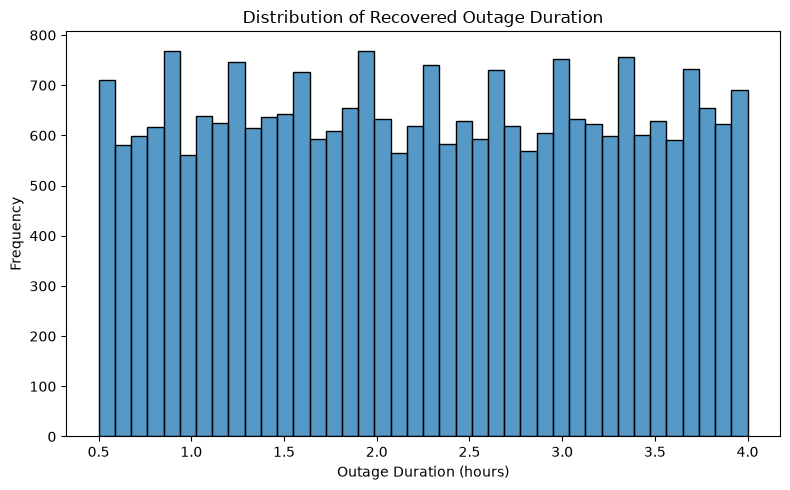

In [34]:

# Outage duration distribution

if not duration_df.empty:
    plt.figure(figsize=(8, 5))
    sns.histplot(
        duration_df["Outage_Duration_Hours"],
        bins=40
    )
    plt.title("Distribution of Recovered Outage Duration")
    plt.xlabel("Outage Duration (hours)")
    plt.ylabel("Frequency")
    plt.tight_layout()
    plt.show()
else:
    print("No recovered outages with valid duration were available for this analysis.")



## 6.2 Data Understanding and EDA — Seasonal Patterns

The project uses these **project-defined seasonal periods**:

- **Summer:** February–May
- **Rainy Season:** June–September
- **Winter:** October–January

These labels are used for this project's analysis and later seasonal test design.


,Outage_Count
Season,
Summer,8112
Rainy Season,9085
Winter,8662


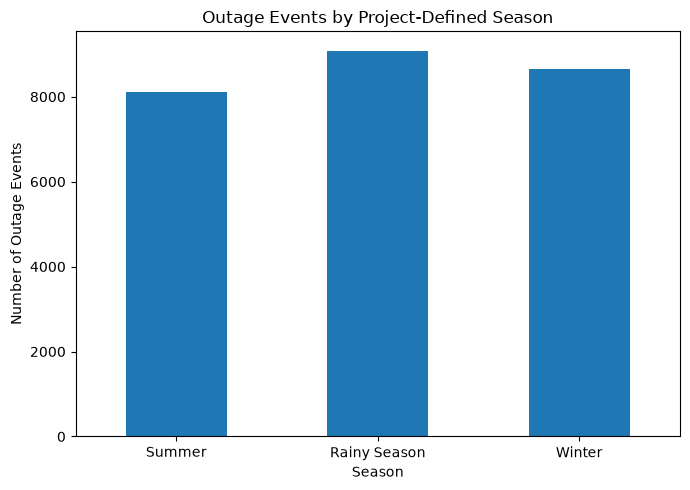

In [35]:

def project_season(month):
    if month in [2, 3, 4, 5]:
        return "Summer"
    if month in [6, 7, 8, 9]:
        return "Rainy Season"
    return "Winter"

outage_with_context["Season"] = (
    outage_with_context["Cell_Down_Time"]
    .dt.month
    .apply(project_season)
)

season_order = [
    "Summer",
    "Rainy Season",
    "Winter"
]

season_counts = (
    outage_with_context["Season"]
    .value_counts()
    .reindex(season_order, fill_value=0)
)

display(
    season_counts.to_frame("Outage_Count")
)

plt.figure(figsize=(7, 5))
season_counts.plot(kind="bar")
plt.title("Outage Events by Project-Defined Season")
plt.xlabel("Season")
plt.ylabel("Number of Outage Events")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()



## 6.2 Data Understanding and EDA — Dataset Relationship Check

Dataset 1 is the network-structure source, while Dataset 2 contains time-based network behavior and events. They are combined conceptually and later in data preparation using `Site_ID + Cell_ID`.

This section checks that Dataset 2 event records can be matched to Dataset 1.


In [36]:

# Coverage of Dataset 2 event cells in Dataset 1

event_cells = set(events_df["Cell_ID"].dropna().astype(str))
master_cells = set(df1["Cell_ID"].dropna().astype(str))

matched = len(event_cells & master_cells)
unmatched = len(event_cells - master_cells)

print("Unique event cells:", f"{len(event_cells):,}")
print("Matched to Dataset 1:", f"{matched:,}")
print("Unmatched:", f"{unmatched:,}")

if len(event_cells) > 0:
    print(
        "Match rate:",
        f"{matched / len(event_cells) * 100:.2f}%"
    )


Unique event cells: 15,438
Matched to Dataset 1: 15,438
Unmatched: 0
Match rate: 100.00%


## 6.2 Additional Analyses — Outage Timing, Network Availability, Pre-Outage Signal and Neighbor Impact

These cells answer instructor comments 2 and 4 and research question RQ2 before any model is trained.

1. **Neighbor lookup:** `Neighbor_Cell_ID` holds a comma-separated list, so it is split into one link per row.
2. **Outage-start timing:** KPI rows are on a 3-hour grid. Under realistic timing about one third of outages start in each hour after a KPI timestamp. A strong pile-up in the first hour would be a generator artifact.
3. **Wider network impact:** Network Availability (%) = (1 − total downtime / total observed cell-time) × 100, by month and technology.
4. **Pre-outage signal (comment 4):** KPIs of the outage cell in the 12 h before the outage are compared with the **same cell, same clock hours, 7 days earlier**. This matched control removes time-of-day and cell-size effects.
5. **Neighbor impact (RQ2):** each neighbor's change from 6 h before to 6 h after the outage is compared with its change 7 days earlier (difference-in-differences).

Comment 2 (outage causes): the dataset has no cause labels. Gradual causes such as congestion should appear as rising Load, Utilization, Latency or Alarm_Count before the outage; sudden causes such as power cuts or fibre cuts leave no warning in KPIs. Item 4 measures how much warning exists.

Neighbor links: 223,003 | mean per cell: 9.74
Share of neighbor links on the same site: 21.3%
Unknown neighbor IDs: 0


,Share of outage starts
0-60 min after a KPI timestamp,33.7%
60-120 min after,32.8%
120-180 min after,33.6%


Uniform timing would give about 33.3% in each band.


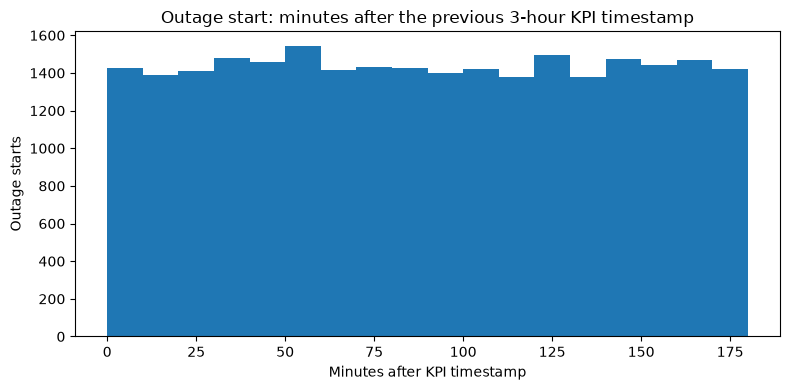

In [37]:
# 6.2A — neighbor lookup, same-site structure and outage-start timing
RANDOM_STATE = 42
edges = df1[["Cell_ID", "Site_ID", "Neighbor_Cell_ID"]].copy()
edges["Neighbor_Cell_ID"] = edges["Neighbor_Cell_ID"].fillna("").astype(str).str.split(",")
edges = edges.explode("Neighbor_Cell_ID")
edges["Neighbor_Cell_ID"] = edges["Neighbor_Cell_ID"].str.strip()
edges = edges[edges["Neighbor_Cell_ID"] != ""]
CELL_SITE = df1.set_index("Cell_ID")["Site_ID"].astype(str).to_dict()
NEIGHBORS = edges.groupby("Cell_ID")["Neighbor_Cell_ID"].apply(list).to_dict()
SITE_CELLS = df1.groupby("Site_ID")["Cell_ID"].apply(list).to_dict()
edges["Same_Site"] = edges["Neighbor_Cell_ID"].map(CELL_SITE) == edges["Site_ID"].astype(str)
print(f"Neighbor links: {len(edges):,} | mean per cell: {edges.groupby('Cell_ID').size().mean():.2f}")
print(f"Share of neighbor links on the same site: {edges['Same_Site'].mean():.1%}")
print("Unknown neighbor IDs:", len(set(edges["Neighbor_Cell_ID"]) - set(df1["Cell_ID"].astype(str))))

out_ev = events_df[events_df["Record_Type"].eq("OUTAGE")].dropna(subset=["Cell_Down_Time"]).copy()
out_ev["Cell_ID"] = out_ev["Cell_ID"].astype(str)
start = out_ev["Cell_Down_Time"]
mins_after_grid = (start - start.dt.floor("3h")).dt.total_seconds() / 60
timing_table = pd.Series({
    "0-60 min after a KPI timestamp": (mins_after_grid < 60).mean(),
    "60-120 min after": ((mins_after_grid >= 60) & (mins_after_grid < 120)).mean(),
    "120-180 min after": (mins_after_grid >= 120).mean(),
}).rename("Share of outage starts")
display(timing_table.map("{:.1%}".format).to_frame())
print("Uniform timing would give about 33.3% in each band.")
plt.figure(figsize=(8, 4))
plt.hist(mins_after_grid, bins=range(0, 181, 10))
plt.title("Outage start: minutes after the previous 3-hour KPI timestamp")
plt.xlabel("Minutes after KPI timestamp"); plt.ylabel("Outage starts")
plt.tight_layout(); plt.show()

Overall network availability 2024-2025: 99.9855%
Total recovered downtime: 58,170 cell-hours


,Availability (%)
Technology,
2G,99.9845
3G,99.9854
4G,99.9856
5G,99.9868


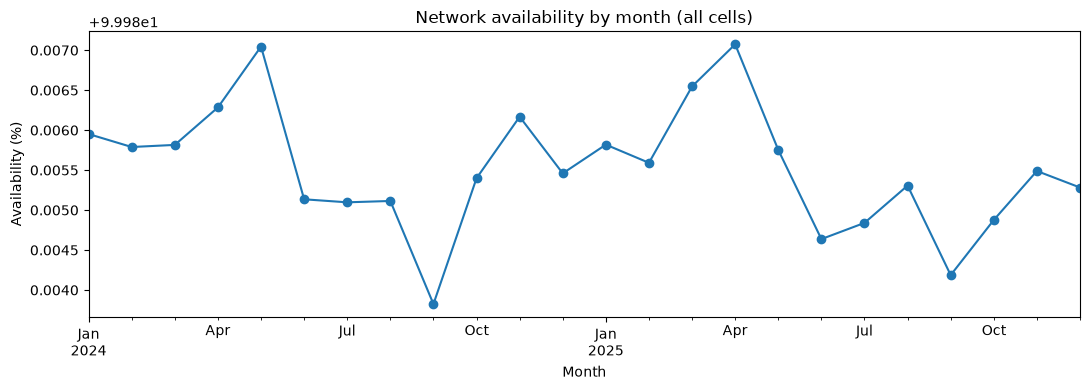

In [38]:
# 6.2B — wider network impact: Network Availability by month and by technology
period_start = pd.Timestamp("2024-01-01")
period_end = pd.Timestamp(max_time)
n_cells = df1["Cell_ID"].nunique()
dd = duration_df.copy()
dd["Month"] = dd["Cell_Down_Time"].dt.to_period("M")   # outages last <= 4 h, so assigned to their start month
down_by_month = dd.groupby("Month")["Outage_Duration_Hours"].sum()
hours_by_month = pd.Series({m: (min(m.end_time, period_end) - max(m.start_time, period_start)).total_seconds() / 3600
                            for m in down_by_month.index})
availability_month = 100 * (1 - down_by_month / (n_cells * hours_by_month))
total_hours = (period_end - period_start).total_seconds() / 3600
overall_availability = 100 * (1 - dd["Outage_Duration_Hours"].sum() / (n_cells * total_hours))
print(f"Overall network availability 2024-2025: {overall_availability:.4f}%")
print(f"Total recovered downtime: {dd['Outage_Duration_Hours'].sum():,.0f} cell-hours")

dd_tech = dd.merge(df1[["Cell_ID", "Technology"]], on="Cell_ID", how="left")
cells_by_tech = df1["Technology"].value_counts()
availability_tech = (100 * (1 - dd_tech.groupby("Technology")["Outage_Duration_Hours"].sum()
                            / (cells_by_tech * total_hours))).rename("Availability (%)")
display(availability_tech.round(4).to_frame())

plt.figure(figsize=(11, 4))
availability_month.plot(marker="o")
plt.title("Network availability by month (all cells)")
plt.ylabel("Availability (%)"); plt.xlabel("Month")
plt.tight_layout(); plt.show()
Path("project_outputs").mkdir(exist_ok=True)
availability_month.rename("Availability_%").to_csv("project_outputs/availability_by_month.csv")

In [39]:
# 6.2C — stream only the KPI rows needed for a random sample of outages (cell + neighbors, nearby days)
N_EVENTS = 300
CONTROL_LAG = pd.Timedelta(days=7)
KPI_COLS = ["Traffic", "Connected_Users", "Throughput", "Latency", "Packet_Loss", "Load", "Capacity", "Alarm_Count"]
ev_sample = out_ev[out_ev["Cell_Down_Time"] >= out_ev["Cell_Down_Time"].min() + pd.Timedelta(days=9)]
ev_sample = ev_sample.sample(min(N_EVENTS, len(ev_sample)), random_state=RANDOM_STATE).reset_index(drop=True)

wanted_keys = set()
for cell, e in zip(ev_sample["Cell_ID"], ev_sample["Cell_Down_Time"]):
    for base in (e, e - CONTROL_LAG):
        for d in (base - pd.Timedelta(days=1), base, base + pd.Timedelta(days=1)):
            day = d.strftime("%Y-%m-%d")
            wanted_keys.update(f"{c}|{day}" for c in [cell] + NEIGHBORS.get(cell, []))

kept, load_gt_cap, kpi_seen = [], 0, 0
for chunk in pd.read_csv(DATASET_2_MERGED_FILE, usecols=["Timestamp", "Cell_ID", "Record_Type"] + KPI_COLS,
                         chunksize=2_000_000, low_memory=False):
    k = chunk[chunk["Record_Type"] == "KPI"]
    kpi_seen += len(k)
    load_gt_cap += int((k["Load"] > k["Capacity"]).sum())
    key = k["Cell_ID"].astype(str) + "|" + k["Timestamp"].astype(str).str[:10]
    kept.append(k[key.isin(wanted_keys)])
kpi_win = pd.concat(kept, ignore_index=True)
kpi_win["Timestamp"] = pd.to_datetime(kpi_win["Timestamp"], format="ISO8601")
kpi_by_cell = {c: g.set_index("Timestamp").sort_index() for c, g in kpi_win.groupby("Cell_ID")}
print(f"Sampled outages: {len(ev_sample)} | KPI rows kept: {len(kpi_win):,}")
print(f"All KPI rows: {kpi_seen:,} | Load > Capacity: {load_gt_cap:,} ({load_gt_cap / kpi_seen:.2%})")

Sampled outages: 300 | KPI rows kept: 155,127
All KPI rows: 133,899,778 | Load > Capacity: 48,673,098 (36.35%)


Outages with both windows: 300


,Median pre-outage,Median control (7 days earlier),Median difference,Share of outages with higher pre-outage value,Wilcoxon p-value
Traffic,6.0010,6.0265,0.0073,0.5133,0.4038
Connected_Users,80.0000,80.0000,-0.5000,0.4633,0.4832
Throughput,4.7682,4.6008,0.0035,0.5200,0.9672
Latency,77.8685,77.3603,-0.1240,0.4933,0.6142
Packet_Loss,0.9065,0.9045,0.0008,0.5033,0.6953
Load,44.9648,45.6985,-0.0815,0.4933,0.5881
Capacity,64.5790,64.5790,0.0000,0.0000,NaN
Alarm_Count,0.0000,0.0000,0.0000,0.0133,0.1797


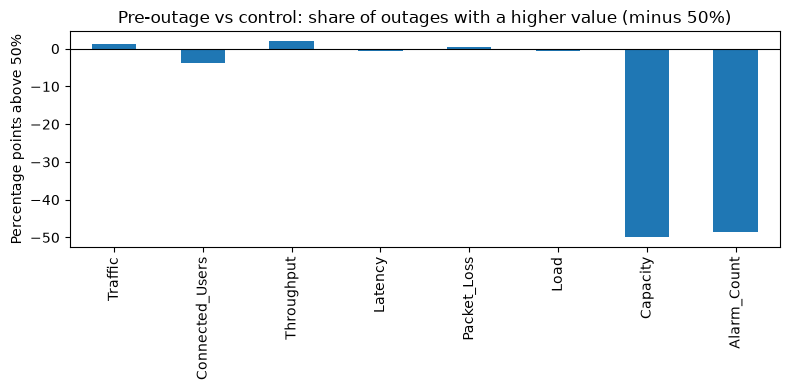

Reading guide: bars near 0 and p-values > 0.05 mean no measurable early-warning signal for that KPI.


In [40]:
# 6.2D — pre-outage signal (comment 4): 12 h before the outage vs the same cell and hours 7 days earlier
def window_median(cell, start, end, closed="left"):
    g = kpi_by_cell.get(cell)
    if g is None:
        return None
    w = g.loc[(g.index >= start) & (g.index < end)] if closed == "left" else g.loc[(g.index > start) & (g.index <= end)]
    return None if w.empty else w[KPI_COLS].median()

pre_rows = []
for cell, e in zip(ev_sample["Cell_ID"], ev_sample["Cell_Down_Time"]):
    pre = window_median(cell, e - pd.Timedelta(hours=12), e)
    ctl = window_median(cell, e - CONTROL_LAG - pd.Timedelta(hours=12), e - CONTROL_LAG)
    if pre is not None and ctl is not None:
        pre_rows.append(pd.concat([pre.add_suffix("_pre"), ctl.add_suffix("_ctl")]))
pre_df = pd.DataFrame(pre_rows)
pre_diff = pd.DataFrame({c: pre_df[f"{c}_pre"] - pre_df[f"{c}_ctl"] for c in KPI_COLS})
pre_summary = pd.DataFrame({
    "Median pre-outage": pre_df[[f"{c}_pre" for c in KPI_COLS]].median().values,
    "Median control (7 days earlier)": pre_df[[f"{c}_ctl" for c in KPI_COLS]].median().values,
    "Median difference": pre_diff.median().values,
    "Share of outages with higher pre-outage value": (pre_diff > 0).mean().values,
}, index=KPI_COLS)
try:
    from scipy.stats import wilcoxon
    pre_summary["Wilcoxon p-value"] = [wilcoxon(pre_diff[c].dropna()).pvalue if pre_diff[c].dropna().ne(0).any() else np.nan
                                       for c in KPI_COLS]
except ImportError:
    print("scipy not installed: p-values skipped")
print("Outages with both windows:", len(pre_df))
display(pre_summary.round(4))
pre_summary.to_csv("project_outputs/pre_outage_signal_vs_control.csv")

plt.figure(figsize=(8, 4))
(pre_diff > 0).mean().sub(0.5).mul(100).plot(kind="bar")
plt.axhline(0, color="black", linewidth=0.8)
plt.title("Pre-outage vs control: share of outages with a higher value (minus 50%)")
plt.ylabel("Percentage points above 50%")
plt.tight_layout(); plt.show()
print("Reading guide: bars near 0 and p-values > 0.05 mean no measurable early-warning signal for that KPI.")

In [41]:
# 6.2E — neighbor impact (RQ2): difference-in-differences against the same neighbor 7 days earlier
SIX = pd.Timedelta(hours=6)
did_rows = []
for cell, e in zip(ev_sample["Cell_ID"], ev_sample["Cell_Down_Time"]):
    for n in NEIGHBORS.get(cell, []):
        b = window_median(n, e - SIX, e)
        a = window_median(n, e, e + SIX, closed="right")
        cb = window_median(n, e - CONTROL_LAG - SIX, e - CONTROL_LAG)
        ca = window_median(n, e - CONTROL_LAG, e - CONTROL_LAG + SIX, closed="right")
        if all(x is not None for x in (b, a, cb, ca)):
            r = (a - b) - (ca - cb)
            r["Same_Site"] = CELL_SITE.get(n) == CELL_SITE.get(cell)
            did_rows.append(r)
did = pd.DataFrame(did_rows)
print("Outage-neighbor pairs analysed:", len(did))
did_summary = pd.DataFrame({
    "Median DiD (all neighbors)": did[KPI_COLS].median(),
    "Share with increase": (did[KPI_COLS] > 0).mean(),
    "Median DiD (same-site neighbors)": did.loc[did["Same_Site"], KPI_COLS].median(),
    "Median DiD (other-site neighbors)": did.loc[~did["Same_Site"], KPI_COLS].median(),
})
display(did_summary.round(4))
did_summary.to_csv("project_outputs/neighbor_impact_did.csv")
print("If traffic really moves to neighbors, Connected_Users/Traffic/Load should show DiD > 0 and a share above 50%.")

Outage-neighbor pairs analysed: 2938


,Median DiD (all neighbors),Share with increase,Median DiD (same-site neighbors),Median DiD (other-site neighbors)
Traffic,0.3042,0.6440,0.2840,0.3057
Connected_Users,3.5000,0.6310,3.5000,3.5000
Throughput,-0.0725,0.3792,-0.0955,-0.0628
Latency,5.6205,0.7015,6.4382,5.3977
Packet_Loss,0.0780,0.6572,0.0870,0.0743
Load,2.8353,0.6937,3.6910,2.6937
Capacity,0.0000,0.0000,0.0000,0.0000
Alarm_Count,0.0000,0.0674,0.0000,0.0000


If traffic really moves to neighbors, Connected_Users/Traffic/Load should show DiD > 0 and a share above 50%.



## 6.2 Data Understanding and EDA — Summary Checklist

After running the notebook, use the actual outputs to document:

**Dataset 1**
- Total sites and cells
- Technology distribution
- Region and district distribution
- Cells per site
- Neighbor count distribution
- Missing values and duplicates

**Dataset 2**
- Total rows and time range
- Number of unique sites and cells
- `KPI / OUTAGE / RECOVERY` counts
- Status distribution
- Missing-value pattern by record type
- KPI descriptive statistics
- KPI distributions, skewness, and outliers
- KPI relationships and correlations
- Utilization distribution
- Outage counts by month, technology, region, district, site, and cell
- Recovered outage duration
- Project-defined seasonal patterns
- Dataset 1 ↔ Dataset 2 matching coverage

### Important boundary for the next stage

This part is **EDA only**.

The following steps come later:

**Data Preparation → Feature Engineering (previous 6 hours) → Leakage Check → Target Creation (`Outage_Next_12h`) → Chronological / unseen-site evaluation → Model Training → Model Evaluation.**

The following future 12-hour information must not be used as predictor features.


## 6.3 Data Cleaning and Preprocessing


This section builds a modelling-ready KPI table from the original Dataset 2. It uses the column names documented in the submitted EDA: `Timestamp`, `Site_ID`, `Cell_ID`, `Record_Type`, `Status`, KPI fields, and outage/recovery event records. It reads only the required columns and processes the large file in chunks.

**Important:** Event rows may legitimately have blank KPI values. Do not drop them from the event table simply because KPI fields are missing. The model table below keeps only `Record_Type == "KPI"`.


## 6.3 Data Cleaning and Preprocessing — Chunked KPI Loading

Reads only KPI rows in chunks and writes `KPI_Model_Data.csv`. Timestamps are parsed with `format="ISO8601"` because midnight rows are stored as a date only (`2024-01-01`) while other rows include a time (`2024-01-01 03:00:00`).

In [42]:
# ============================================================
# 6.3 Data Cleaning and Preprocessing — Chunked KPI Loading
# ============================================================

from pathlib import Path
import pandas as pd

# Reuse the existing Dataset 1 and Dataset 2 paths
print("Dataset 1 exists:", Path(DATASET_1_FILE).is_file())
print("Dataset 2 exists:", Path(DATASET_2_MERGED_FILE).is_file())

if not Path(DATASET_2_MERGED_FILE).is_file():
    raise FileNotFoundError(
        f"Dataset 2 not found: {DATASET_2_MERGED_FILE}"
    )

# Check actual Dataset 2 columns
schema_cols = pd.read_csv(
    DATASET_2_MERGED_FILE,
    nrows=0
).columns.tolist()

print("Dataset 2 columns:", schema_cols)

required_cols = [
    "Timestamp", "Site_ID", "Cell_ID", "Record_Type",
    "Traffic", "Connected_Users", "Throughput",
    "Latency", "Packet_Loss", "Load", "Capacity",
    "Alarm_Count", "Previous_Outage_Count"
]

available_cols = [
    col for col in required_cols if col in schema_cols
]

missing_cols = [
    col for col in required_cols if col not in schema_cols
]

print("Missing optional/model columns:", missing_cols)

# Essential columns must exist
essential = ["Timestamp", "Site_ID", "Cell_ID", "Record_Type"]

if not set(essential).issubset(schema_cols):
    raise ValueError(
        "Dataset 2 is missing essential columns."
    )

# Save cleaned KPI records on D drive
OUTPUT_FILE = Path(
    r"D:\Dataset\Uganda_Cell_Telecom_Dataset"
    r"\Dataset_2_Cell_KPI_Outage\KPI_Model_Data.csv"
)

OUTPUT_FILE.parent.mkdir(parents=True, exist_ok=True)

if OUTPUT_FILE.exists():
    OUTPUT_FILE.unlink()

chunk_size = globals().get("CSV_CHUNK_SIZE", 50_000)
total_rows = 0
first_chunk = True

for chunk in pd.read_csv(
    DATASET_2_MERGED_FILE,
    usecols=available_cols,
    chunksize=chunk_size,
    dtype={
        "Timestamp": "string",
        "Site_ID": "string",
        "Cell_ID": "string",
        "Record_Type": "string"
    },
    on_bad_lines="error"
):
    # Select KPI records
    mask = (
        chunk["Record_Type"]
        .str.strip()
        .str.upper()
        .eq("KPI")
    )

    kpi = chunk.loc[mask].copy()

    if kpi.empty:
        continue

    # Clean timestamps and numeric fields
    # FIX: midnight rows are stored as "2024-01-01" (date only) and other rows as
    # "2024-01-01 03:00:00". Without format="ISO8601", pandas infers ONE format per chunk
    # and turns the other format into NaT, which silently dropped ~15.8 million KPI rows.
    kpi["Timestamp"] = pd.to_datetime(
        kpi["Timestamp"], format="ISO8601", errors="coerce"
    )
    n_bad = int(kpi["Timestamp"].isna().sum())
    if n_bad:
        print(f"WARNING: {n_bad} unparseable timestamps in this chunk")

    numeric_cols = [
        col for col in available_cols
        if col not in essential
    ]

    for col in numeric_cols:
        kpi[col] = pd.to_numeric(
            kpi[col], errors="coerce"
        )

    kpi = kpi.dropna(
        subset=["Timestamp", "Site_ID", "Cell_ID"]
    )

    # Remove duplicates within this chunk
    kpi = kpi.drop_duplicates(
        subset=["Timestamp", "Site_ID", "Cell_ID"]
    )

    if not kpi.empty:
        # Write one uniform timestamp format so DuckDB (Section 6.4) does not infer DATE
        # from the first midnight rows and then fail on rows that include a time.
        kpi["Timestamp"] = kpi["Timestamp"].dt.strftime("%Y-%m-%d %H:%M:%S")
        kpi.to_csv(
            OUTPUT_FILE,
            mode="w" if first_chunk else "a",
            header=first_chunk,
            index=False
        )

        first_chunk = False
        total_rows += len(kpi)

print("\nKPI loading completed.")
print(f"KPI rows saved: {total_rows:,}")
print("Expected KPI rows from Section 6.2: 133,908,458 -> difference:", f"{133_908_458 - total_rows:,}")
print(f"Output file: {OUTPUT_FILE}")

# Display only a small sample
if total_rows > 0:
    sample = pd.read_csv(OUTPUT_FILE, nrows=5)
    display(sample)
else:
    print("No KPI records found. Check Record_Type values.")

Dataset 1 exists: True
Dataset 2 exists: True
Dataset 2 columns: ['Timestamp', 'Site_ID', 'Cell_ID', 'Record_Type', 'Status', 'Traffic', 'Connected_Users', 'Throughput', 'Latency', 'Packet_Loss', 'Load', 'Capacity', 'Alarm_Count', 'Previous_Outage_Count', 'Cell_Down_Time', 'Cell_Up_Time']
Missing optional/model columns: []

KPI loading completed.
KPI rows saved: 133,899,778
Expected KPI rows from Section 6.2: 133,908,458 -> difference: 8,680
Output file: D:\Dataset\Uganda_Cell_Telecom_Dataset\Dataset_2_Cell_KPI_Outage\KPI_Model_Data.csv


,Timestamp,Site_ID,Cell_ID,Record_Type,Traffic,Connected_Users,Throughput,Latency,Packet_Loss,Load,Capacity,Alarm_Count,Previous_Outage_Count
0,2024-01-01 00:00:00,UG-BUS-1658,UG-BUS-1658-S02,KPI,2.129,23.0,1.306,64.562,0.320,20.428,34.391,0.0,0
1,2024-01-01 00:00:00,UG-MBA-5831,UG-MBA-5831-S04,KPI,20.941,138.0,33.760,31.910,0.797,203.920,178.489,0.0,0
2,2024-01-01 00:00:00,UG-KIT-2854,UG-KIT-2854-S04,KPI,24.122,80.0,79.612,41.128,1.047,331.371,307.217,0.0,0
3,2024-01-01 00:00:00,UG-ARU-5548,UG-ARU-5548-S03,KPI,13.871,30.0,35.882,44.813,0.302,116.953,151.059,0.0,0
4,2024-01-01 00:00:00,UG-KLA-0402,UG-KLA-0402-S01,KPI,0.475,25.0,0.210,139.754,0.871,8.629,18.711,0.0,0


## 6.4 Feature Engineering


Create features from information available at the prediction timestamp only. The submitted EDA calculates utilization from `Load` and `Capacity`; this section also creates past-observation lags, rolling means, and trends. Future outage/event fields are not model predictors.


## 6.4 Feature Engineering — Utilization and Historical KPI Features

The next code cell uses DuckDB and disk-based hash partitions because the KPI table is too large to safely load and sort as one Pandas DataFrame. Features are calculated in timestamp order within each Cell_ID. The rolling average excludes the current row. Intermediate Parquet files are written under `feature_work` on D: drive.


In [43]:
%pip install duckdb

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.0 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [44]:
# ============================================================
# 6.4 Feature Engineering — Utilization and Historical KPI Features
# Disk-based processing for large Dataset 2
# ============================================================

from pathlib import Path
import duckdb
import shutil

INPUT_FILE = Path(
    r"D:\Dataset\Uganda_Cell_Telecom_Dataset"
    r"\Dataset_2_Cell_KPI_Outage\KPI_Model_Data.csv"
)
OUTPUT_FILE = Path(
    r"D:\Dataset\Uganda_Cell_Telecom_Dataset"
    r"\Dataset_2_Cell_KPI_Outage\KPI_Feature_Data.csv"
)

WORK_DIR = OUTPUT_FILE.parent / "feature_work"
PARTITION_DIR = WORK_DIR / "input_partitions"
FEATURE_DIR = WORK_DIR / "feature_partitions"
TEMP_DIR = WORK_DIR / "duckdb_temp"
DB_FILE = WORK_DIR / "feature_processing.duckdb"
N_PARTITIONS = 256

if not INPUT_FILE.is_file():
    raise FileNotFoundError(f"KPI input file not found: {INPUT_FILE}")
if INPUT_FILE.resolve() == OUTPUT_FILE.resolve():
    raise ValueError("Input and output paths must be different.")

WORK_DIR.mkdir(parents=True, exist_ok=True)
for folder in [PARTITION_DIR, FEATURE_DIR]:
    if folder.exists():
        shutil.rmtree(folder)
    folder.mkdir(parents=True, exist_ok=True)
TEMP_DIR.mkdir(parents=True, exist_ok=True)

con = duckdb.connect(str(DB_FILE))
con.execute("SET memory_limit = '1GB'")
con.execute("SET threads = 1")
con.execute("SET preserve_insertion_order = false")

source = str(INPUT_FILE).replace("\\", "/").replace("'", "''")
destination = str(OUTPUT_FILE).replace("\\", "/").replace("'", "''")
temp_sql = str(TEMP_DIR).replace("\\", "/").replace("'", "''")
partition_dir_sql = str(PARTITION_DIR).replace("\\", "/").replace("'", "''")

try:
    columns = [
        row[0] for row in con.execute(
            f"DESCRIBE SELECT * FROM read_csv_auto('{source}', sample_size=10000)"
        ).fetchall()
    ]
    print("Input columns:", columns)

    required = [
        "Timestamp", "Site_ID", "Cell_ID", "Traffic", "Connected_Users",
        "Throughput", "Latency", "Packet_Loss", "Load", "Capacity"
    ]
    missing = [c for c in required if c not in columns]
    if missing:
        raise ValueError(f"Required columns missing from KPI input: {missing}")

    numeric_features = [
        c for c in [
            "Traffic", "Connected_Users", "Throughput", "Latency",
            "Packet_Loss", "Alarm_Count", "Load", "Capacity"
        ] if c in columns
    ]

    con.execute(f"SET temp_directory = '{temp_sql}'")

    # Each Cell_ID hashes to one bucket, keeping its complete history together.
    # The bucket value is encoded in the folder name, not the Parquet columns.
    print("\nStep 1/3: Partitioning input data...")
    con.execute(f"""
        COPY (
            SELECT
                *,
                TRY_CAST("Timestamp" AS TIMESTAMP) AS ts,
                CAST(HASH("Cell_ID") % {N_PARTITIONS} AS INTEGER) AS bucket
            FROM read_csv_auto('{source}', sample_size=10000)
            WHERE TRY_CAST("Timestamp" AS TIMESTAMP) IS NOT NULL
              AND "Site_ID" IS NOT NULL
              AND "Cell_ID" IS NOT NULL
        )
        TO '{partition_dir_sql}'
        (FORMAT PARQUET, PARTITION_BY (bucket), COMPRESSION ZSTD)
    """)

    feature_columns = numeric_features + ["Utilization"]
    feature_expressions = []
    for col in feature_columns:
        qcol = '"' + col.replace('"', '""') + '"'
        feature_expressions.extend([
            f'''LAG(TRY_CAST({qcol} AS DOUBLE), 1)
                OVER (PARTITION BY "Cell_ID" ORDER BY ts) AS "{col}_lag1"''',
            f'''LAG(TRY_CAST({qcol} AS DOUBLE), 2)
                OVER (PARTITION BY "Cell_ID" ORDER BY ts) AS "{col}_lag2"''',
            f'''AVG(TRY_CAST({qcol} AS DOUBLE))
                OVER (PARTITION BY "Cell_ID" ORDER BY ts
                      ROWS BETWEEN 3 PRECEDING AND 1 PRECEDING)
                AS "{col}_mean_previous3"''',
            f'''TRY_CAST({qcol} AS DOUBLE)
                - LAG(TRY_CAST({qcol} AS DOUBLE), 2)
                  OVER (PARTITION BY "Cell_ID" ORDER BY ts)
                AS "{col}_trend2"'''
        ])
    feature_sql = ",\n".join(feature_expressions)

    print("\nStep 2/3: Engineering historical KPI features...")
    processed = 0
    total_feature_rows = 0

    for bucket in range(N_PARTITIONS):
        bucket_folder = PARTITION_DIR / f"bucket={bucket}"
        if not bucket_folder.exists() or not list(bucket_folder.glob("*.parquet")):
            continue

        bucket_input = str(bucket_folder / "*.parquet").replace("\\", "/").replace("'", "''")
        bucket_output = FEATURE_DIR / f"features_{bucket:03d}.parquet"
        bucket_output_sql = str(bucket_output).replace("\\", "/").replace("'", "''")

        # Do not EXCLUDE bucket: partition keys are stored in folder names,
        # and hive_partitioning=False means bucket is absent from Parquet columns.
        con.execute(f"""
            COPY (
                WITH source_data AS (
                    SELECT *
                    FROM read_parquet('{bucket_input}', hive_partitioning = false)
                ),
                cleaned AS (
                    SELECT *
                    FROM source_data
                    QUALIFY ROW_NUMBER() OVER (
                        PARTITION BY ts, "Site_ID", "Cell_ID"
                        ORDER BY ts
                    ) = 1
                ),
                derived AS (
                    SELECT
                        * EXCLUDE ("Timestamp", ts),
                        ts AS "Timestamp",
                        CASE
                            WHEN TRY_CAST("Capacity" AS DOUBLE) > 0
                            THEN TRY_CAST("Load" AS DOUBLE)
                                 / TRY_CAST("Capacity" AS DOUBLE) * 100
                            ELSE NULL
                        END AS "Utilization",
                        ts
                    FROM cleaned
                ),
                featured AS (
                    SELECT *, {feature_sql}
                    FROM derived
                )
                SELECT * EXCLUDE (ts)
                FROM featured
            )
            TO '{bucket_output_sql}'
            (FORMAT PARQUET, COMPRESSION ZSTD)
        """)

        rows = con.execute(
            f"SELECT COUNT(*) FROM read_parquet('{bucket_output_sql}')"
        ).fetchone()[0]
        total_feature_rows += rows
        processed += 1
        if processed % 10 == 0:
            print(f"Processed {processed} partitions; rows so far: {total_feature_rows:,}")

    if processed == 0:
        raise RuntimeError("No partitions were processed; inspect the input data and paths.")

    print("\nStep 3/3: Writing final feature CSV...")
    feature_glob = str(FEATURE_DIR / "*.parquet").replace("\\", "/").replace("'", "''")
    if OUTPUT_FILE.exists():
        OUTPUT_FILE.unlink()

    con.execute(f"""
        COPY (SELECT * FROM read_parquet('{feature_glob}'))
        TO '{destination}' (HEADER, DELIMITER ',')
    """)

    output_rows = con.execute(
        f"SELECT COUNT(*) FROM read_csv_auto('{destination}', sample_size=1000)"
    ).fetchone()[0]
    sample = con.execute(
        f"SELECT * FROM read_csv_auto('{destination}', sample_size=1000) LIMIT 5"
    ).fetchdf()

    print("\nFeature engineering completed.")
    print("Partitions processed:", processed)
    print(f"Rows in partition outputs: {total_feature_rows:,}")
    print(f"Rows in final CSV: {output_rows:,}")
    print("Output file:", OUTPUT_FILE)
    print(f"Output size: {OUTPUT_FILE.stat().st_size / (1024**3):.2f} GB")
    if output_rows != total_feature_rows:
        print("WARNING: final row count differs from partition outputs.")
    display(sample)

finally:
    con.close()
    print("\nDuckDB connection closed.")


Input columns: ['Timestamp', 'Site_ID', 'Cell_ID', 'Record_Type', 'Traffic', 'Connected_Users', 'Throughput', 'Latency', 'Packet_Loss', 'Load', 'Capacity', 'Alarm_Count', 'Previous_Outage_Count']

Step 1/3: Partitioning input data...

Step 2/3: Engineering historical KPI features...
Processed 10 partitions; rows so far: 5,203,951
Processed 20 partitions; rows so far: 10,425,449
Processed 30 partitions; rows so far: 15,623,573
Processed 40 partitions; rows so far: 21,073,132
Processed 50 partitions; rows so far: 26,066,594
Processed 60 partitions; rows so far: 31,492,761
Processed 70 partitions; rows so far: 36,731,807
Processed 80 partitions; rows so far: 41,813,007
Processed 90 partitions; rows so far: 46,765,578
Processed 100 partitions; rows so far: 51,823,363
Processed 110 partitions; rows so far: 57,109,188
Processed 120 partitions; rows so far: 62,892,012
Processed 130 partitions; rows so far: 68,218,749
Processed 140 partitions; rows so far: 73,644,890
Processed 150 partitions; 

,Site_ID,Cell_ID,Record_Type,Traffic,Connected_Users,Throughput,Latency,Packet_Loss,Load,Capacity,Alarm_Count,Previous_Outage_Count,Timestamp,Utilization,Traffic_lag1,Traffic_lag2,Traffic_mean_previous3,Traffic_trend2,Connected_Users_lag1,Connected_Users_lag2,Connected_Users_mean_previous3,Connected_Users_trend2,Throughput_lag1,Throughput_lag2,Throughput_mean_previous3,Throughput_trend2,Latency_lag1,Latency_lag2,Latency_mean_previous3,Latency_trend2,Packet_Loss_lag1,Packet_Loss_lag2,Packet_Loss_mean_previous3,Packet_Loss_trend2,Alarm_Count_lag1,Alarm_Count_lag2,Alarm_Count_mean_previous3,Alarm_Count_trend2,Load_lag1,Load_lag2,Load_mean_previous3,Load_trend2,Capacity_lag1,Capacity_lag2,Capacity_mean_previous3,Capacity_trend2,Utilization_lag1,Utilization_lag2,Utilization_mean_previous3,Utilization_trend2
0,UG-BSH-5399,UG-BSH-5399-S02,KPI,3.484,23.0,1.529,77.677,0.542,29.753,59.054,0.0,0,2024-01-01 00:00:00,50.382701,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,UG-BSH-5399,UG-BSH-5399-S02,KPI,3.173,21.0,1.480,78.940,0.517,29.529,59.054,0.0,0,2024-01-01 03:00:00,50.003387,3.484,NaN,3.484000,NaN,23.0,NaN,23.000000,NaN,1.529,NaN,1.529000,NaN,77.677,NaN,77.677000,NaN,0.542,NaN,0.542000,NaN,0.0,NaN,0.0,NaN,29.753,NaN,29.753,NaN,59.054,NaN,59.054,NaN,50.382701,NaN,50.382701,NaN
2,UG-BSH-5399,UG-BSH-5399-S02,KPI,5.862,34.0,2.333,73.755,0.556,30.583,59.054,0.0,0,2024-01-01 06:00:00,51.788194,3.173,3.484,3.328500,2.378,21.0,23.0,22.000000,11.0,1.480,1.529,1.504500,0.804,78.940,77.677,78.308500,-3.922,0.517,0.542,0.529500,0.014,0.0,0.0,0.0,0.0,29.529,29.753,29.641,0.830,59.054,59.054,59.054,0.0,50.003387,50.382701,50.193044,1.405493
3,UG-BSH-5399,UG-BSH-5399-S02,KPI,5.093,40.0,3.021,71.723,0.597,35.102,59.054,0.0,0,2024-01-01 09:00:00,59.440512,5.862,3.173,4.173000,1.920,34.0,21.0,26.000000,19.0,2.333,1.480,1.780667,1.541,73.755,78.940,76.790667,-7.217,0.556,0.517,0.538333,0.080,0.0,0.0,0.0,0.0,30.583,29.529,29.955,5.573,59.054,59.054,59.054,0.0,51.788194,50.003387,50.724760,9.437125
4,UG-BSH-5399,UG-BSH-5399-S02,KPI,6.306,44.0,2.768,76.731,0.525,39.880,59.054,0.0,0,2024-01-01 12:00:00,67.531412,5.093,5.862,4.709333,0.444,40.0,34.0,31.666667,10.0,3.021,2.333,2.278000,0.435,71.723,73.755,74.806000,2.976,0.597,0.556,0.556667,-0.031,0.0,0.0,0.0,0.0,35.102,30.583,31.738,9.297,59.054,59.054,59.054,0.0,59.440512,51.788194,53.744031,15.743218



DuckDB connection closed.


In [45]:
import numpy as np
import pandas as pd

print("NumPy:", np.__version__)

feature_file = r"D:\Dataset\Uganda_Cell_Telecom_Dataset\Dataset_2_Cell_KPI_Outage\KPI_Feature_Data.csv"
display(pd.read_csv(feature_file, nrows=5))

NumPy: 2.5.2


,Site_ID,Cell_ID,Record_Type,Traffic,Connected_Users,Throughput,Latency,Packet_Loss,Load,Capacity,Alarm_Count,Previous_Outage_Count,Timestamp,Utilization,Traffic_lag1,Traffic_lag2,Traffic_mean_previous3,Traffic_trend2,Connected_Users_lag1,Connected_Users_lag2,Connected_Users_mean_previous3,Connected_Users_trend2,Throughput_lag1,Throughput_lag2,Throughput_mean_previous3,Throughput_trend2,Latency_lag1,Latency_lag2,Latency_mean_previous3,Latency_trend2,Packet_Loss_lag1,Packet_Loss_lag2,Packet_Loss_mean_previous3,Packet_Loss_trend2,Alarm_Count_lag1,Alarm_Count_lag2,Alarm_Count_mean_previous3,Alarm_Count_trend2,Load_lag1,Load_lag2,Load_mean_previous3,Load_trend2,Capacity_lag1,Capacity_lag2,Capacity_mean_previous3,Capacity_trend2,Utilization_lag1,Utilization_lag2,Utilization_mean_previous3,Utilization_trend2
0,UG-BSH-5399,UG-BSH-5399-S02,KPI,3.484,23.0,1.529,77.677,0.542,29.753,59.054,0.0,0,2024-01-01 00:00:00,50.382701,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,UG-BSH-5399,UG-BSH-5399-S02,KPI,3.173,21.0,1.480,78.940,0.517,29.529,59.054,0.0,0,2024-01-01 03:00:00,50.003387,3.484,NaN,3.484000,NaN,23.0,NaN,23.000000,NaN,1.529,NaN,1.529000,NaN,77.677,NaN,77.677000,NaN,0.542,NaN,0.542000,NaN,0.0,NaN,0.0,NaN,29.753,NaN,29.753,NaN,59.054,NaN,59.054,NaN,50.382701,NaN,50.382701,NaN
2,UG-BSH-5399,UG-BSH-5399-S02,KPI,5.862,34.0,2.333,73.755,0.556,30.583,59.054,0.0,0,2024-01-01 06:00:00,51.788194,3.173,3.484,3.328500,2.378,21.0,23.0,22.000000,11.0,1.480,1.529,1.504500,0.804,78.940,77.677,78.308500,-3.922,0.517,0.542,0.529500,0.014,0.0,0.0,0.0,0.0,29.529,29.753,29.641,0.830,59.054,59.054,59.054,0.0,50.003387,50.382701,50.193044,1.405493
3,UG-BSH-5399,UG-BSH-5399-S02,KPI,5.093,40.0,3.021,71.723,0.597,35.102,59.054,0.0,0,2024-01-01 09:00:00,59.440512,5.862,3.173,4.173000,1.920,34.0,21.0,26.000000,19.0,2.333,1.480,1.780667,1.541,73.755,78.940,76.790667,-7.217,0.556,0.517,0.538333,0.080,0.0,0.0,0.0,0.0,30.583,29.529,29.955,5.573,59.054,59.054,59.054,0.0,51.788194,50.003387,50.724760,9.437125
4,UG-BSH-5399,UG-BSH-5399-S02,KPI,6.306,44.0,2.768,76.731,0.525,39.880,59.054,0.0,0,2024-01-01 12:00:00,67.531412,5.093,5.862,4.709333,0.444,40.0,34.0,31.666667,10.0,3.021,2.333,2.278000,0.435,71.723,73.755,74.806000,2.976,0.597,0.556,0.556667,-0.031,0.0,0.0,0.0,0.0,35.102,30.583,31.738,9.297,59.054,59.054,59.054,0.0,59.440512,51.788194,53.744031,15.743218


## 6.5 Target / Label Creation — `Outage_Next_12h`


The target is 1 if an outage starts strictly after the prediction timestamp and no later than 12 hours after it; otherwise it is 0. Outage start times are taken from `Cell_Down_Time` on `OUTAGE` rows (identical to `Timestamp` on those rows).

Only future event times are used to create the target. Event fields themselves must not be used as model features.

## 6.5 Target / Label Creation and 6.6 Split — Code

One cell builds the labels, the chronological and unseen-site splits, and a memory-safe modelling sample.

In [46]:
print({name: name in globals() for name in ["df1", "events_df", "max_time"]})

{'df1': True, 'events_df': True, 'max_time': True}


In [47]:
# ============================================================
# 6.5 Target creation + 6.6 requested seasonal split
# Train: first full year (2024); Validation: first month of each season in 2025;
# Temporal test: second month of each season in 2025; Unseen-site test: same test months
# on 2,000 held-out sites. This cell does not guarantee high scores; it creates a
# leakage-aware evaluation design and reports the actual results.
# ============================================================
from pathlib import Path
import numpy as np
import pandas as pd

FEATURE_FILE = Path(r"D:\Dataset\Uganda_Cell_Telecom_Dataset\Dataset_2_Cell_KPI_Outage\KPI_Feature_Data.csv")
RANDOM_STATE = 42
HORIZON = pd.Timedelta(hours=12)
STEP = pd.Timedelta(hours=3)
N_UNSEEN_SITES = 2000
NEG_FRAC_TRAIN = 0.01       # keep all positives and a random 1% of negative training rows
EVAL_CELL_FRAC = 0.05       # sample 5% of cells for seen-site validation/test to limit RAM
CHUNK = 500_000
rng = np.random.default_rng(RANDOM_STATE)

# Dates: first year for training; months chosen from the user's seasonal definitions.
TRAIN_START = pd.Timestamp("2024-01-01")
TRAIN_END = pd.Timestamp("2025-01-01")
VALIDATION_MONTHS = {(2025, 2), (2025, 6), (2025, 10)}  # Feb, Jun, Oct: first month of each season
TEMPORAL_TEST_MONTHS = {(2025, 3), (2025, 7), (2025, 11)}  # Mar, Jul, Nov: second month of each season

required = {"Site_ID", "Cell_ID", "Timestamp"}
if not required.issubset(set(pd.read_csv(FEATURE_FILE, nrows=0).columns)):
    raise ValueError(f"Feature file must contain columns: {sorted(required)}")
if "events_df" not in globals() or "df1" not in globals() or "max_time" not in globals():
    raise NameError("Before running this cell, define events_df, df1, and max_time in earlier notebook cells.")

# Positive keys: a prediction at t is positive if the same cell has an outage start in (t, t+12h].
out = events_df.loc[
    events_df["Record_Type"].astype(str).str.upper().eq("OUTAGE"),
    ["Cell_ID", "Cell_Down_Time"]
].dropna().copy()
out["Cell_ID"] = out["Cell_ID"].astype(str)
out["Cell_Down_Time"] = pd.to_datetime(out["Cell_Down_Time"], errors="coerce")
out = out.dropna(subset=["Cell_Down_Time"]).drop_duplicates()

pos_rows = []
for cell, event_time in zip(out["Cell_ID"], out["Cell_Down_Time"]):
    # Align to the 3-hour KPI grid. If event is exactly on a grid point, the previous
    # grid point is the last valid prediction time strictly before the outage.
    t = event_time.floor("3h")
    if t == event_time:
        t -= STEP
    while t >= event_time - HORIZON:
        pos_rows.append((cell, t))
        t -= STEP
pos = pd.DataFrame(pos_rows, columns=["Cell_ID", "Timestamp"]).drop_duplicates()
pos["Timestamp"] = pd.to_datetime(pos["Timestamp"], errors="coerce")
pos["Outage_Next_12h"] = np.int8(1)
OBS_END = pd.Timestamp(max_time) - HORIZON
print(f"Unique outage event rows used: {len(out):,}")
print(f"Positive (Cell_ID, Timestamp) keys: {len(pos):,}")
print(f"Rows after {OBS_END} are excluded because the complete 12-hour horizon is unavailable.")

# Hold out 2,000 sites. These sites must not occur in training or seen-site validation/test.
site_ids = np.array(sorted(df1["Site_ID"].dropna().astype(str).unique()))
if len(site_ids) <= N_UNSEEN_SITES:
    raise ValueError(f"Need more than {N_UNSEEN_SITES} sites to hold out {N_UNSEEN_SITES} and retain training sites; found {len(site_ids)}.")
unseen_sites = set(rng.choice(site_ids, N_UNSEEN_SITES, replace=False))
cell_info = df1[[c for c in ["Cell_ID", "Technology", "Region", "Township"] if c in df1.columns]].copy()
cell_info["Cell_ID"] = cell_info["Cell_ID"].astype(str)
cell_info = cell_info.drop_duplicates("Cell_ID")
all_cells = np.array(sorted(df1["Cell_ID"].dropna().astype(str).unique()))
seen_cells = np.array([c for c in all_cells if c not in set(df1.loc[df1["Site_ID"].astype(str).isin(unseen_sites), "Cell_ID"].astype(str))])
eval_cells = set(rng.choice(seen_cells, max(1, int(len(seen_cells) * EVAL_CELL_FRAC)), replace=False))

split_names = ["train", "validation", "temporal_test", "unseen_test"]
parts = {k: [] for k in split_names}
population = {k: [0, 0] for k in split_names}  # eligible rows and positives before modelling sampling

for chunk in pd.read_csv(FEATURE_FILE, chunksize=CHUNK, dtype={"Site_ID": "string", "Cell_ID": "string"}):
    missing = required - set(chunk.columns)
    if missing:
        raise ValueError(f"Feature file is missing required columns: {sorted(missing)}")
    chunk["Site_ID"] = chunk["Site_ID"].astype("string")
    chunk["Cell_ID"] = chunk["Cell_ID"].astype("string")
    chunk["Timestamp"] = pd.to_datetime(chunk["Timestamp"], errors="coerce")
    chunk = chunk[chunk["Timestamp"].notna() & (chunk["Timestamp"] >= TRAIN_START) & (chunk["Timestamp"] <= OBS_END)].copy()
    if chunk.empty:
        continue
    numeric_cols = chunk.select_dtypes(include=["number"]).columns
    chunk[numeric_cols] = chunk[numeric_cols].astype("float32")
    chunk = chunk.merge(pos, on=["Cell_ID", "Timestamp"], how="left", validate="many_to_one")
    chunk["Outage_Next_12h"] = chunk["Outage_Next_12h"].fillna(0).astype("int8")
    months = list(zip(chunk["Timestamp"].dt.year, chunk["Timestamp"].dt.month))
    in_train_year = (chunk["Timestamp"] < TRAIN_END).to_numpy()
    val_mask = np.array([m in VALIDATION_MONTHS for m in months])
    test_mask = np.array([m in TEMPORAL_TEST_MONTHS for m in months])
    is_unseen = chunk["Site_ID"].astype(str).isin(unseen_sites).to_numpy()
    split = np.full(len(chunk), "drop", dtype=object)
    split[in_train_year & ~is_unseen] = "train"
    split[val_mask & ~is_unseen] = "validation"
    split[test_mask & ~is_unseen] = "temporal_test"
    split[test_mask & is_unseen] = "unseen_test"

    for name in split_names:
        s = chunk[split == name].copy()
        if s.empty:
            continue
        population[name][0] += len(s)
        population[name][1] += int(s["Outage_Next_12h"].sum())
        if name == "train":
            keep = (s["Outage_Next_12h"].to_numpy() == 1) | (rng.random(len(s)) < NEG_FRAC_TRAIN)
        elif name in ("validation", "temporal_test"):
            keep = s["Cell_ID"].astype(str).isin(eval_cells).to_numpy()
        else:
            # Keep all rows for held-out sites during the specified seasonal test months.
            keep = np.ones(len(s), dtype=bool)
        if keep.any():
            parts[name].append(s.loc[keep].copy())

frames = {}
for name, chunks in parts.items():
    if not chunks:
        frames[name] = pd.DataFrame()
        continue
    frame = pd.concat(chunks, ignore_index=True)
    # Merge only metadata not already present to avoid _x/_y duplicate columns.
    metadata_cols = [c for c in cell_info.columns if c != "Cell_ID" and c not in frame.columns]
    if metadata_cols:
        frame = frame.merge(cell_info[["Cell_ID"] + metadata_cols], on="Cell_ID", how="left", validate="many_to_one")
    frames[name] = frame

train_df = frames["train"]
validation_df = frames["validation"]
temporal_test_df = frames["temporal_test"]
unseen_test = frames["unseen_test"]

# Report original class balance before sampling and actual modelling frame sizes.
rows = []
for name, frame in frames.items():
    n_all, positives = population[name]
    kept_pos = int(frame["Outage_Next_12h"].sum()) if not frame.empty else 0
    rows.append({
        "Split": name,
        "Eligible rows before sampling": n_all,
        "Eligible positives before sampling": positives,
        "Eligible positive rate (%)": round(100 * positives / n_all, 5) if n_all else np.nan,
        "Rows kept for modelling": len(frame),
        "Kept positives": kept_pos,
        "Kept positive rate (%)": round(100 * kept_pos / len(frame), 5) if len(frame) else np.nan,
        "Date range": f"{frame['Timestamp'].min()} to {frame['Timestamp'].max()}" if not frame.empty else "EMPTY",
        "Unique sites": frame["Site_ID"].nunique() if not frame.empty else 0,
        "Unique cells": frame["Cell_ID"].nunique() if not frame.empty else 0,
    })
class_balance = pd.DataFrame(rows)
display(class_balance)
Path("project_outputs").mkdir(exist_ok=True)
class_balance.to_csv("project_outputs/class_balance_by_split.csv", index=False)

# Mandatory integrity checks; these raise errors rather than silently accepting bad splits.
if train_df.empty or validation_df.empty or temporal_test_df.empty or unseen_test.empty:
    raise ValueError("One or more splits are empty. Check the date range, event labels, and input files.")
train_sites = set(train_df["Site_ID"].astype(str).unique())
unseen_test_sites = set(unseen_test["Site_ID"].astype(str).unique())
if train_sites & unseen_test_sites:
    raise AssertionError("Leakage: unseen-site test contains a site present in training.")
if not unseen_test_sites.issubset(unseen_sites):
    raise AssertionError("Unseen-site test contains a site not selected for the held-out group.")
print("Seasonal split created.")
print("Training period: 2024-01-01 through 2024-12-31, seen sites only.")
print("Validation months: February, June, October 2025, seen-site cell sample.")
print("Temporal test months: March, July, November 2025, seen-site cell sample.")
print(f"Unseen-site test: {len(unseen_test_sites):,} held-out sites represented in March/July/November 2025.")
print("Training/unseen-site overlap: 0 (verified).")


Unique outage event rows used: 25,859
Positive (Cell_ID, Timestamp) keys: 103,417
Rows after 2025-12-31 11:57:29 are excluded because the complete 12-hour horizon is unavailable.


,Split,Eligible rows before sampling,Eligible positives before sampling,Eligible positive rate (%),Rows kept for modelling,Kept positives,Kept positive rate (%),Date range,Unique sites,Unique cells
0,train,44718720,34539,0.07724,480999,34539,7.18068,2024-01-01 00:00:00 to 2024-12-31 21:00:00,4000,15275
1,validation,10874155,8494,0.07811,543152,510,0.09390,2025-02-01 00:00:00 to 2025-10-31 21:00:00,705,763
2,temporal_test,11240819,8563,0.07618,561496,373,0.06643,2025-03-01 00:00:00 to 2025-11-30 21:00:00,705,763
3,unseen_test,5611182,4335,0.07726,5611182,4335,0.07726,2025-03-01 00:00:00 to 2025-11-30 21:00:00,2000,7625


Seasonal split created.
Training period: 2024-01-01 through 2024-12-31, seen sites only.
Validation months: February, June, October 2025, seen-site cell sample.
Temporal test months: March, July, November 2025, seen-site cell sample.
Unseen-site test: 2,000 held-out sites represented in March/July/November 2025.
Training/unseen-site overlap: 0 (verified).


## Step 6. Train / Validation / Test Split — Seasonal Design

- **Training:** 1 January–31 December 2024, using seen sites only. Keep all positive rows and randomly sample 1% of negative training rows to reduce memory use. Report original class prevalence before sampling.
- **Seasonal validation:** the first month of each defined season in 2025: **February (summer), June (rainy), October (winter)**. Use this set to compare models and choose thresholds.
- **Seasonal temporal test:** the second month of each season in 2025: **March (summer), July (rainy), November (winter)**. Use this set only for final evaluation after model/threshold selection.
- **Unseen-site test:** the same temporal-test months for a randomly selected group of **2,000 held-out sites**. These sites are excluded from training and seen-site validation/test. All eligible rows from the held-out sites are retained for the unseen-site test.
- KPI timestamps whose full future 12-hour label horizon is not observable are excluded. The notebook checks that training and unseen-test sites do not overlap.

The seasonal month choices follow the project’s definitions: summer = February–May, rainy = June–September, winter = October–January. Results must be interpreted from actual outputs; this split design does not guarantee high prediction scores.

## 6.6 Train / Validation / Test Split — Summary

The next code cell reports the rows, sites, cells, date ranges, and positive rates for the four groups. Check `project_outputs/class_balance_by_split.csv` after running. A split with no positive cases cannot support meaningful recall/PR-AUC interpretation and must be reported as a limitation rather than concealed.

In [48]:
# Split summary (the split itself is created in the previous cell)
for split_name, split_df in [("Train (down-sampled)", train_df), ("Validation", validation_df),
                             ("Temporal test", temporal_test_df), ("Unseen-site test", unseen_test)]:
    print(f"{split_name:22s} rows: {len(split_df):>10,} | cells: {split_df['Cell_ID'].nunique():>6,} "
          f"| positive rate: {split_df['Outage_Next_12h'].mean():.4%}")
overlap = set(train_df["Site_ID"]) & set(unseen_test["Site_ID"])
print("Unseen-test sites that appear in training:", len(overlap), "(must be 0)")

Train (down-sampled)   rows:    480,999 | cells: 15,275 | positive rate: 7.1807%
Validation             rows:    543,152 | cells:    763 | positive rate: 0.0939%
Temporal test          rows:    561,496 | cells:    763 | positive rate: 0.0664%
Unseen-site test       rows:  5,611,182 | cells:  7,625 | positive rate: 0.0773%
Unseen-test sites that appear in training: 0 (must be 0)


## 6.7 Model Implementation


Compare an operational threshold baseline with Logistic Regression and Random Forest. The baseline thresholds below are illustrative rules for comparison, not verified operator standards. Preprocessing is fitted using training data only. Identifiers, timestamps, target, and any direct outage/event columns are excluded from model predictors.


## 6.7 Model Implementation — Code

In [49]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    precision_score, recall_score, f1_score, average_precision_score,
    confusion_matrix, classification_report, precision_recall_curve
)

# Explicitly exclude identifiers and potential direct/future leakage columns.
excluded = {
    "Site_ID", "Cell_ID", "Timestamp", "Record_Type", "Status", "Split",
    "Outage_Next_12h", "Availability", "Outage_Duration",
    "Site_Down_Time", "Site_Up_Time", "Cell_Down_Time", "Cell_Up_Time"
}
feature_cols = [
    c for c in train_df.columns
    if c not in excluded
    and not any(term in c.lower() for term in ["outage_start", "recovery_time", "down_time", "up_time"])
    and (pd.api.types.is_numeric_dtype(train_df[c]) or c in ["Technology", "Region", "Township"])
]
print("Predictor columns:", feature_cols)
if not feature_cols:
    raise ValueError("No eligible predictors found. Review schema and leakage exclusions.")

X_train = train_df[feature_cols].copy()
y_train = train_df["Outage_Next_12h"].astype(int)
X_val = validation_df[feature_cols].copy()
y_val = validation_df["Outage_Next_12h"].astype(int)

# pandas 3 stores text as dtype "str", which the old check missed -> use "not numeric"
categorical_cols = [c for c in feature_cols if not pd.api.types.is_numeric_dtype(X_train[c])]
numeric_cols = [c for c in feature_cols if c not in categorical_cols]

numeric_preprocess = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])
categorical_preprocess = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])
preprocessor = ColumnTransformer([
    ("numeric", numeric_preprocess, numeric_cols),
    ("categorical", categorical_preprocess, categorical_cols)
], remainder="drop")

models = {
    "Logistic Regression": Pipeline([
        ("preprocess", preprocessor),
        ("model", LogisticRegression(max_iter=2000, random_state=42))
    ]),
    "Random Forest": Pipeline([
        ("preprocess", preprocessor),
        ("model", RandomForestClassifier(
            n_estimators=150, min_samples_leaf=20, max_features="sqrt",
            n_jobs=-1, random_state=42
            # no class_weight: the training set is already balanced by down-sampling negatives
        ))
    ])
}

fitted_models = {}
for model_name, model in models.items():
    if y_train.nunique() < 2:
        raise ValueError("Training split contains only one target class; inspect target and split.")
    print("Training:", model_name)
    model.fit(X_train, y_train)
    fitted_models[model_name] = model

print("Trained models:", list(fitted_models))

Predictor columns: ['Traffic', 'Connected_Users', 'Throughput', 'Latency', 'Packet_Loss', 'Load', 'Capacity', 'Alarm_Count', 'Previous_Outage_Count', 'Utilization', 'Traffic_lag1', 'Traffic_lag2', 'Traffic_mean_previous3', 'Traffic_trend2', 'Connected_Users_lag1', 'Connected_Users_lag2', 'Connected_Users_mean_previous3', 'Connected_Users_trend2', 'Throughput_lag1', 'Throughput_lag2', 'Throughput_mean_previous3', 'Throughput_trend2', 'Latency_lag1', 'Latency_lag2', 'Latency_mean_previous3', 'Latency_trend2', 'Packet_Loss_lag1', 'Packet_Loss_lag2', 'Packet_Loss_mean_previous3', 'Packet_Loss_trend2', 'Alarm_Count_lag1', 'Alarm_Count_lag2', 'Alarm_Count_mean_previous3', 'Alarm_Count_trend2', 'Load_lag1', 'Load_lag2', 'Load_mean_previous3', 'Load_trend2', 'Capacity_lag1', 'Capacity_lag2', 'Capacity_mean_previous3', 'Capacity_trend2', 'Utilization_lag1', 'Utilization_lag2', 'Utilization_mean_previous3', 'Utilization_trend2', 'Technology', 'Region']
Training: Logistic Regression
Training: Ran

## 6.8 Model Evaluation


Evaluate precision, recall, F1-score, PR-AUC (average precision), confusion matrix, and false alarms per site-day. Accuracy is not used alone because outage labels may be imbalanced. Report temporal-test and unseen-site results separately.


## 6.8 Model Evaluation — Validation, Threshold Tuning and Rule Baselines

In [50]:
def operational_threshold_prediction(frame, utilization_threshold=85.0, alarm_threshold=3):
    pred = np.zeros(len(frame), dtype=int)
    has_rule = False
    if "Utilization" in frame.columns:
        pred |= (pd.to_numeric(frame["Utilization"], errors="coerce").fillna(-np.inf).to_numpy() >= utilization_threshold).astype(int)
        has_rule = True
    if "Alarm_Count" in frame.columns:
        pred |= (pd.to_numeric(frame["Alarm_Count"], errors="coerce").fillna(-np.inf).to_numpy() >= alarm_threshold).astype(int)
        has_rule = True
    if not has_rule:
        print("Warning: utilization and alarm-count columns unavailable; baseline defaults to all-negative.")
    return pred

def false_alarms_per_site_day(y_true, y_pred, frame):
    false_positives = int(((np.asarray(y_true) == 0) & (np.asarray(y_pred) == 1)).sum())
    if len(frame) and {"Site_ID", "Timestamp"}.issubset(frame.columns):
        site_days = frame.assign(_day=frame["Timestamp"].dt.floor("D"))[["Site_ID", "_day"]].drop_duplicates().shape[0]
        return false_positives / site_days if site_days else np.nan
    return np.nan

def evaluate_predictions(label, y_true, y_pred, y_score, frame):
    row = {
        "Evaluation": label,
        "Precision": precision_score(y_true, y_pred, zero_division=0),
        "Recall": recall_score(y_true, y_pred, zero_division=0),
        "F1_score": f1_score(y_true, y_pred, zero_division=0),
        "PR_AUC_Average_Precision": average_precision_score(y_true, y_score) if len(np.unique(y_true)) == 2 else np.nan,
        "False_alarms_per_site_day": false_alarms_per_site_day(y_true, y_pred, frame),
        "Positive_rate": float(np.mean(y_true)) if len(y_true) else np.nan
    }
    print("\\n", label)
    print(classification_report(y_true, y_pred, zero_division=0))
    print("Confusion matrix [[TN, FP], [FN, TP]]:")
    print(confusion_matrix(y_true, y_pred, labels=[0, 1]))
    return row

def best_f1_threshold(y_true, scores):
    """Threshold that maximises F1 on validation. Down-sampled training shifts the
    probability scale, so 0.5 is not meaningful; the threshold is chosen on validation only."""
    precision, recall, thresholds = precision_recall_curve(y_true, scores)
    f1 = 2 * precision * recall / np.clip(precision + recall, 1e-12, None)
    best = int(np.nanargmax(f1[:-1])) if len(thresholds) else 0
    return float(thresholds[best]) if len(thresholds) else 0.5

evaluation_rows, chosen_threshold = [], {}
for model_name, model in fitted_models.items():
    val_scores = model.predict_proba(X_val)[:, 1]
    chosen_threshold[model_name] = best_f1_threshold(y_val, val_scores)
    val_pred = (val_scores >= chosen_threshold[model_name]).astype(int)
    evaluation_rows.append(evaluate_predictions(
        f"{model_name} — validation (threshold {chosen_threshold[model_name]:.3f})",
        y_val, val_pred, val_scores, validation_df))

# Rule baselines: thresholds are tuned on validation too (not fixed guesses), so the comparison is fair.
rule_grid = [(u, a) for u in [100, 125, 150, 200, 250, np.inf] for a in [1, 2, 3, np.inf] if not (u == np.inf and a == np.inf)]
rule_scores = []
for u, a in rule_grid:
    pred = operational_threshold_prediction(validation_df, utilization_threshold=u, alarm_threshold=a)
    rule_scores.append((f1_score(y_val, pred, zero_division=0), u, a))
best_rule_f1, BEST_UTIL, BEST_ALARM = max(rule_scores)
print(f"Best rule on validation: Utilization >= {BEST_UTIL} OR Alarm_Count >= {BEST_ALARM} (F1 = {best_rule_f1:.4f})")
baseline_val = operational_threshold_prediction(validation_df, BEST_UTIL, BEST_ALARM)
evaluation_rows.append(evaluate_predictions(
    "Rule baseline (tuned) — validation", y_val, baseline_val, baseline_val.astype(float), validation_df))
alarm_only = operational_threshold_prediction(validation_df, np.inf, 1)
evaluation_rows.append(evaluate_predictions(
    "Rule: Alarm_Count >= 1 — validation", y_val, alarm_only, validation_df["Alarm_Count"].fillna(0).to_numpy(), validation_df))
validation_results = pd.DataFrame(evaluation_rows)
display(validation_results)

\n Logistic Regression — validation (threshold 0.081)
              precision    recall  f1-score   support

           0       1.00      0.94      0.97    542642
           1       0.00      0.08      0.00       510

    accuracy                           0.94    543152
   macro avg       0.50      0.51      0.49    543152
weighted avg       1.00      0.94      0.97    543152

Confusion matrix [[TN, FP], [FN, TP]]:
[[511731  30911]
 [   470     40]]
\n Random Forest — validation (threshold 0.182)
              precision    recall  f1-score   support

           0       1.00      1.00      1.00    542642
           1       0.02      0.01      0.01       510

    accuracy                           1.00    543152
   macro avg       0.51      0.51      0.51    543152
weighted avg       1.00      1.00      1.00    543152

Confusion matrix [[TN, FP], [FN, TP]]:
[[542350    292]
 [   504      6]]
Best rule on validation: Utilization >= inf OR Alarm_Count >= 1 (F1 = 0.0017)
\n Rule baseline (

,Evaluation,Precision,Recall,F1_score,PR_AUC_Average_Precision,False_alarms_per_site_day,Positive_rate
0,Logistic Regression — validation (threshold 0....,0.001292,0.078431,0.002543,0.001074,0.492645,0.000939
1,Random Forest — validation (threshold 0.182),0.020134,0.011765,0.014851,0.001316,0.004654,0.000939
2,Rule baseline (tuned) — validation,0.000897,0.015686,0.001698,0.000938,0.141940,0.000939
3,Rule: Alarm_Count >= 1 — validation,0.000897,0.015686,0.001698,0.000937,0.141940,0.000939


## 6.8 Model Evaluation — Later-Time and Unseen-Site Evaluation

In [51]:
# Select the model by validation PR-AUC (threshold-free and suited to rare outages).
validation_pr_auc = {name: average_precision_score(y_val, m.predict_proba(X_val)[:, 1])
                     for name, m in fitted_models.items()}
best_model_name = max(validation_pr_auc, key=validation_pr_auc.get)
best_model = fitted_models[best_model_name]
print("Validation PR-AUC:", {k: round(v, 5) for k, v in validation_pr_auc.items()})
print("Selected:", best_model_name, "| threshold from validation:", round(chosen_threshold[best_model_name], 4))

final_rows = []
for frame, label in [(temporal_test_df, "later temporal test"), (unseen_test, "unseen-site test")]:
    if frame.empty:
        print(label, "is empty; skipped.")
        continue
    X, y = frame[feature_cols], frame["Outage_Next_12h"].astype(int)
    for name, m in fitted_models.items():
        scores = m.predict_proba(X)[:, 1]
        pred = (scores >= chosen_threshold[name]).astype(int)
        final_rows.append(evaluate_predictions(f"{name} — {label}", y, pred, scores, frame))
    rule = operational_threshold_prediction(frame, BEST_UTIL, BEST_ALARM)
    final_rows.append(evaluate_predictions(f"Rule baseline (tuned) — {label}", y, rule, rule.astype(float), frame))

final_results = pd.DataFrame(final_rows)
display(final_results)
print("Reference: PR-AUC of random guessing = positive rate of each test set.")

output_folder = Path("project_outputs")
output_folder.mkdir(exist_ok=True)
validation_results.to_csv(output_folder / "validation_metrics.csv", index=False)
final_results.to_csv(output_folder / "final_test_metrics.csv", index=False)
print("Metrics saved to:", output_folder.resolve())

Validation PR-AUC: {'Logistic Regression': 0.00107, 'Random Forest': 0.00132}
Selected: Random Forest | threshold from validation: 0.1819
\n Logistic Regression — later temporal test
              precision    recall  f1-score   support

           0       1.00      0.94      0.97    561123
           1       0.00      0.07      0.00       373

    accuracy                           0.94    561496
   macro avg       0.50      0.50      0.49    561496
weighted avg       1.00      0.94      0.97    561496

Confusion matrix [[TN, FP], [FN, TP]]:
[[528402  32721]
 [   348     25]]
\n Random Forest — later temporal test
              precision    recall  f1-score   support

           0       1.00      1.00      1.00    561123
           1       0.00      0.00      0.00       373

    accuracy                           1.00    561496
   macro avg       0.50      0.50      0.50    561496
weighted avg       1.00      1.00      1.00    561496

Confusion matrix [[TN, FP], [FN, TP]]:
[[560831   

,Evaluation,Precision,Recall,F1_score,PR_AUC_Average_Precision,False_alarms_per_site_day,Positive_rate
0,Logistic Regression — later temporal test,0.000763,0.067024,0.001510,0.000721,0.504487,0.000664
1,Random Forest — later temporal test,0.000000,0.000000,0.000000,0.000691,0.004502,0.000664
2,Rule baseline (tuned) — later temporal test,0.001068,0.026810,0.002055,0.000675,0.144172,0.000664
3,Logistic Regression — unseen-site test,0.000913,0.067128,0.001801,0.000857,1.730723,0.000773
4,Random Forest — unseen-site test,0.003425,0.000461,0.000813,0.000836,0.003163,0.000773
5,Rule baseline (tuned) — unseen-site test,0.000893,0.019146,0.001706,0.000775,0.504837,0.000773


Reference: PR-AUC of random guessing = positive rate of each test set.
Metrics saved to: C:\Users\User\Downloads\project_outputs


## 6.8 Model Evaluation — Diagnostics: PR Curves, Confusion Matrix, Feature Importance, Results by Technology

Objective 3 asks for the features that drive outage risk. Random Forest importances and Logistic Regression coefficients are reported side by side; they describe the model, not proven causes.

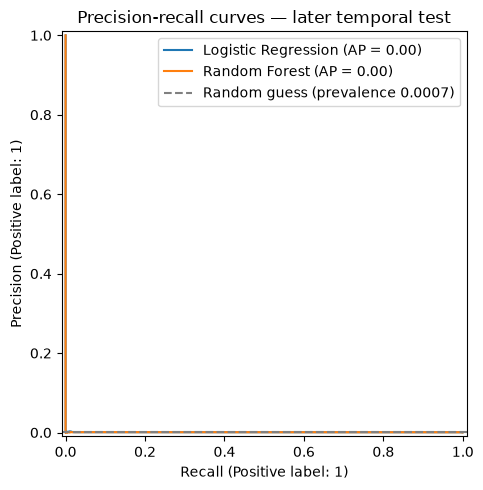

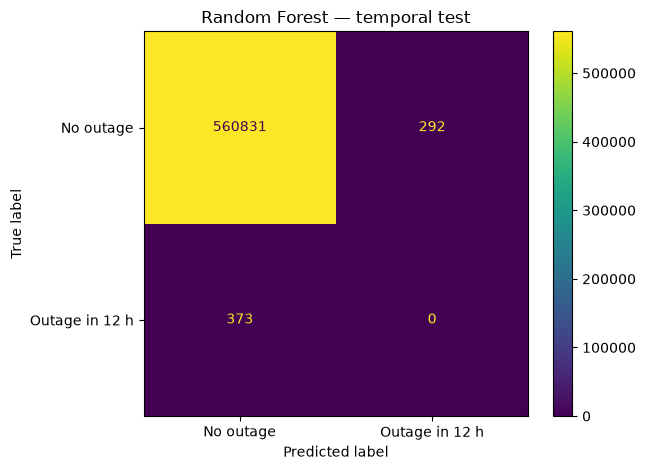

,RF importance,LR coefficient (standardized)
numeric__Latency_trend2,0.0284,0.0149
numeric__Packet_Loss_mean_previous3,0.0280,-0.0234
numeric__Latency_mean_previous3,0.0276,-0.0807
numeric__Throughput_trend2,0.0273,0.0088
numeric__Latency,0.0272,0.0366
numeric__Packet_Loss_lag1,0.0272,0.0138
numeric__Packet_Loss,0.0272,0.0026
numeric__Traffic_trend2,0.0271,0.0015
numeric__Latency_lag1,0.0268,0.0166
numeric__Packet_Loss_lag2,0.0267,0.0176


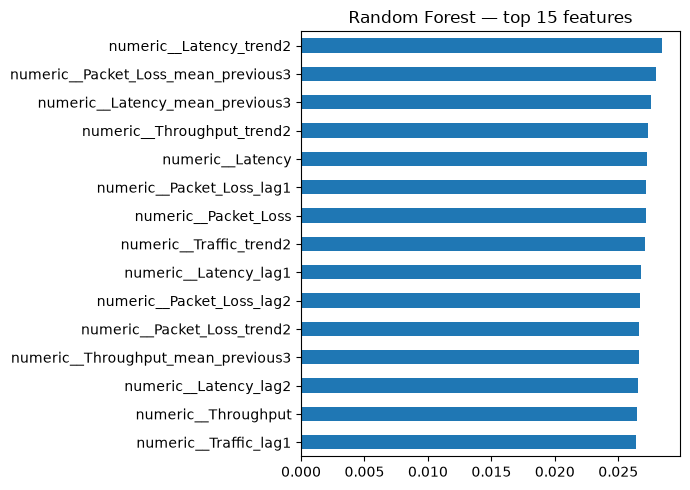

,Technology,Rows,Positive rate,PR-AUC,Recall
0,2G,162642,0.0005,0.0009,0.0
1,3G,136136,0.0009,0.0007,0.0
2,4G,146438,0.0008,0.0008,0.0
3,5G,116280,0.0004,0.0005,0.0


In [52]:
from sklearn.metrics import PrecisionRecallDisplay, ConfusionMatrixDisplay
X_te, y_te = temporal_test_df[feature_cols], temporal_test_df["Outage_Next_12h"].astype(int)
test_scores = {name: m.predict_proba(X_te)[:, 1] for name, m in fitted_models.items()}

fig, ax = plt.subplots(figsize=(7, 5))
for name, sc in test_scores.items():
    PrecisionRecallDisplay.from_predictions(y_te, sc, name=name, ax=ax)
ax.axhline(y_te.mean(), linestyle="--", color="grey", label=f"Random guess (prevalence {y_te.mean():.4f})")
ax.set_title("Precision-recall curves — later temporal test"); ax.legend()
plt.tight_layout(); plt.savefig("project_outputs/pr_curves_temporal_test.png", dpi=160); plt.show()

best_pred = (test_scores[best_model_name] >= chosen_threshold[best_model_name]).astype(int)
ConfusionMatrixDisplay.from_predictions(y_te, best_pred, display_labels=["No outage", "Outage in 12 h"])
plt.title(f"{best_model_name} — temporal test"); plt.tight_layout(); plt.show()

rf = fitted_models["Random Forest"]
names = rf.named_steps["preprocess"].get_feature_names_out()
rf_imp = pd.Series(rf.named_steps["model"].feature_importances_, index=names).sort_values(ascending=False)
lr = fitted_models["Logistic Regression"]
lr_coef = pd.Series(lr.named_steps["model"].coef_[0], index=lr.named_steps["preprocess"].get_feature_names_out())
importance = pd.DataFrame({"RF importance": rf_imp, "LR coefficient (standardized)": lr_coef}).sort_values("RF importance", ascending=False)
display(importance.head(20).round(4))
importance.to_csv("project_outputs/feature_importance.csv")
rf_imp.head(15).iloc[::-1].plot(kind="barh", figsize=(7, 5), title="Random Forest — top 15 features")
plt.tight_layout(); plt.savefig("project_outputs/rf_feature_importance.png", dpi=160); plt.show()

by_tech = []
for tech, idx in temporal_test_df.groupby("Technology").groups.items():
    yt, st = y_te.loc[idx], pd.Series(test_scores[best_model_name], index=y_te.index).loc[idx]
    by_tech.append({"Technology": tech, "Rows": len(idx), "Positive rate": yt.mean(),
                    "PR-AUC": average_precision_score(yt, st) if yt.nunique() == 2 else np.nan,
                    "Recall": recall_score(yt, (st >= chosen_threshold[best_model_name]).astype(int), zero_division=0)})
by_tech = pd.DataFrame(by_tech)
display(by_tech.round(4))
by_tech.to_csv("project_outputs/results_by_technology.csv", index=False)

## 6.9 Neighboring-Cell and Shared-Site (Cascading) Features — Additional RQ

**Question:** does information about neighboring and same-site cells improve prediction of `Outage_Next_12h`, especially for shared-site or cascading failures?

**Features (all known at prediction time *t*, past 6 hours only):**
- `Nbr_Outage_Starts_6h` — outage starts among the cell's mapped neighbors in (*t* − 6 h, *t*]
- `Nbr_Down_Now` — neighbors that are down at *t*
- `Site_Outage_Starts_6h` — outage starts among the other cells on the same site in (*t* − 6 h, *t*]
- `Site_Down_Now` — other same-site cells down at *t*

**Design:** the same split, sample and thresholds procedure as Section 6.8; only the feature set changes. First the cell checks whether such events are more common before outages than at other times; if not, the generator contains no cascading mechanism and neighbor features cannot help.

In [ ]:
%run -i "../scripts/prepare_section_6_9a.py"   # helper for Section 6.9; see README

In [60]:
# 6.9A — build event-based neighbor and shared-site features
from collections import Counter
STEP = pd.Timedelta(hours=3)
LOOKBACK = pd.Timedelta(hours=6)
up_lookup = dict(zip(zip(duration_df["Cell_ID"].astype(str), duration_df["Cell_Down_Time"]), duration_df["Cell_Up_Time"]))
data_end = pd.Timestamp(max_time)
nbr_starts, nbr_down, site_starts, site_down = Counter(), Counter(), Counter(), Counter()
for cell, e in zip(out_ev["Cell_ID"], out_ev["Cell_Down_Time"]):
    u = up_lookup.get((cell, e), data_end)
    nbrs = NEIGHBORS.get(cell, [])
    mates = [c for c in SITE_CELLS.get(CELL_SITE.get(cell), []) if c != cell]
    t = e.ceil("3h")
    while t < e + LOOKBACK:                     # outage start e lies in (t - 6h, t]
        for n in nbrs: nbr_starts[(n, t)] += 1
        for m in mates: site_starts[(m, t)] += 1
        t += STEP
    t = e.ceil("3h")
    while t < u:                                # the cell is down at t
        for n in nbrs: nbr_down[(n, t)] += 1
        for m in mates: site_down[(m, t)] += 1
        t += STEP

NBR_COLS = ["Nbr_Outage_Starts_6h", "Nbr_Down_Now", "Site_Outage_Starts_6h", "Site_Down_Now"]
def add_neighbor_features(frame):
    keys = list(zip(frame["Cell_ID"].astype(str), frame["Timestamp"]))
    for col, counter in zip(NBR_COLS, [nbr_starts, nbr_down, site_starts, site_down]):
        frame[col] = np.array([counter.get(k, 0) for k in keys], dtype="float32")
    return frame

for frame in [train_df, validation_df, temporal_test_df, unseen_test]:
    add_neighbor_features(frame)

# Is there a cascading pattern at all? Compare positives with negatives in the evaluation data.
evaldata = pd.concat([validation_df, temporal_test_df], ignore_index=True)
any_site = (evaldata["Site_Outage_Starts_6h"] + evaldata["Site_Down_Now"]) > 0
any_nbr = (evaldata["Nbr_Outage_Starts_6h"] + evaldata["Nbr_Down_Now"]) > 0
cascade_check = pd.DataFrame({
    "Rows with a same-site outage in the previous 6 h (%)": [100 * any_site[evaldata["Outage_Next_12h"] == g].mean() for g in (1, 0)],
    "Rows with a neighbor outage in the previous 6 h (%)": [100 * any_nbr[evaldata["Outage_Next_12h"] == g].mean() for g in (1, 0)],
}, index=["Outage in next 12 h (positive)", "No outage (negative)"])
display(cascade_check.round(3))
cascade_check.to_csv("project_outputs/cascade_check.csv")
print("If the positive row is clearly higher, outages cluster on sites/neighbors (cascading); if similar, they are independent.")

,Rows with a same-site outage in the previous 6 h (%),Rows with a neighbor outage in the previous 6 h (%)
Outage in next 12 h (positive),0.340,0.793
No outage (negative),0.102,0.379


If the positive row is clearly higher, outages cluster on sites/neighbors (cascading); if similar, they are independent.


In [61]:
# 6.9B — own-cell features vs own-cell + neighbor/shared-site features (same split, same procedure)
from sklearn.base import clone
feature_sets = {"Own-cell features": feature_cols, "Own-cell + neighbor/shared-site": feature_cols + NBR_COLS}
comparison = []
for set_name, cols in feature_sets.items():
    num = [c for c in cols if c not in categorical_cols]
    prep = ColumnTransformer([("numeric", numeric_preprocess, num), ("categorical", categorical_preprocess, categorical_cols)])
    for model_name, template in models.items():
        m = clone(template).set_params(preprocess=prep)
        m.fit(train_df[cols], y_train)
        val_s = m.predict_proba(validation_df[cols])[:, 1]
        thr = best_f1_threshold(y_val, val_s)
        row = {"Feature set": set_name, "Model": model_name, "Validation PR-AUC": average_precision_score(y_val, val_s)}
        for frame, label in [(temporal_test_df, "Temporal test"), (unseen_test, "Unseen-site test")]:
            yt = frame["Outage_Next_12h"].astype(int)
            st = m.predict_proba(frame[cols])[:, 1]
            pt = (st >= thr).astype(int)
            row[f"{label} PR-AUC"] = average_precision_score(yt, st)
            row[f"{label} Recall"] = recall_score(yt, pt, zero_division=0)
            row[f"{label} Precision"] = precision_score(yt, pt, zero_division=0)
        comparison.append(row)
        print("done:", set_name, "|", model_name)
neighbor_comparison = pd.DataFrame(comparison)
display(neighbor_comparison.round(4))
neighbor_comparison.to_csv("project_outputs/neighbor_feature_comparison.csv", index=False)

done: Own-cell features | Logistic Regression
done: Own-cell features | Random Forest
done: Own-cell + neighbor/shared-site | Logistic Regression
done: Own-cell + neighbor/shared-site | Random Forest


,Feature set,Model,Validation PR-AUC,Temporal test PR-AUC,Temporal test Recall,Temporal test Precision,Unseen-site test PR-AUC,Unseen-site test Recall,Unseen-site test Precision
0,Own-cell features,Logistic Regression,0.0011,0.0007,0.0670,0.0008,0.0009,0.0671,0.0009
1,Own-cell features,Random Forest,0.0013,0.0007,0.0000,0.0000,0.0008,0.0005,0.0034
2,Own-cell + neighbor/shared-site,Logistic Regression,0.0011,0.0007,0.0617,0.0008,0.0009,0.0607,0.0009
3,Own-cell + neighbor/shared-site,Random Forest,0.0014,0.0007,0.0000,0.0000,0.0008,0.0000,0.0000


# 7. Progress and Preliminary Results

This section must be updated only after the relevant Section 6 code has been run and its outputs checked. Do not copy expected outcomes as if they were measured findings.

## 7.1 Completed Work and Execution Status

- **Status:** Pending verification after running the notebook from top to bottom.
- Record which cells ran successfully, any errors, and which tasks are complete.

## 7.2 Preliminary EDA Findings

- **Status:** Pending verification from actual EDA tables and plots.
- Summarize missingness, KPI distributions, outliers, correlations, utilization, and outage patterns only when supported by outputs.

## 7.3 Outage Impact Findings

- **Status:** Pending verification from event-aligned affected-cell and neighboring-cell KPI analysis.
- Report observed changes in load, traffic, connected users, throughput, latency, or packet loss where data supports the comparison.

## 7.4 Preliminary Model Evaluation Results

- **Status:** Pending model execution and output verification.
- Insert measured precision, recall, F1-score, PR-AUC, confusion matrix, false alarms per site-day, split details, and class distribution where available.

## 7.5 Neighbor-Feature Experiment Results

- **Status:** Pending a fair comparison of models with and without neighboring-cell features.
- Use the same split and comparable evaluation settings for both experiments.

## 7.6 Remaining Issues and Limitations

- Record unresolved data/code issues, analyses not yet run, uncertainty about outage causes, class imbalance, and synthetic-to-real transfer limitations.

**Important:** Having code does not mean a result is verified. Leave items marked **Pending** until they have been executed successfully and checked. Do not invent numerical results.

In [63]:
%pip install tabulate

     ---------------------------------------- 0.0/40.8 kB ? eta -:--:--
     ------------------- ------------------ 20.5/40.8 kB 320.0 kB/s eta 0:00:01
     ---------------------------- --------- 30.7/40.8 kB 325.1 kB/s eta 0:00:01
     -------------------------------------- 40.8/40.8 kB 324.9 kB/s eta 0:00:00
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.0 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [64]:
# 7.0 — collect every measured result into one summary (only numbers produced by cells that ran)
summary_lines = ["# Preliminary results (generated from notebook outputs)", ""]
def add(title, obj):
    summary_lines.append(f"## {title}")
    if obj is None:
        summary_lines.append("Not available — the cell that produces it has not run.")
    elif isinstance(obj, (pd.DataFrame, pd.Series)):
        summary_lines.append(obj.round(4).to_markdown() if hasattr(obj, "to_markdown") else obj.round(4).to_string())
    else:
        summary_lines.append(str(obj))
    summary_lines.append("")
g = globals()
add("Class balance by split (comment 3)", g.get("class_balance"))
add("Outage-start timing vs KPI grid", g.get("timing_table"))
add("Overall network availability (%)", round(g["overall_availability"], 4) if "overall_availability" in g else None)
add("Availability by technology (%)", g.get("availability_tech"))
add("Pre-outage signal vs matched control (comment 4)", g.get("pre_summary"))
add("Neighbor impact, difference-in-differences (RQ2)", g.get("did_summary"))
add("Validation metrics", g.get("validation_results"))
add("Test metrics (temporal and unseen-site)", g.get("final_results"))
add("Top features", g["importance"].head(10) if "importance" in g else None)
add("Results by technology", g.get("by_tech"))
add("Cascading check", g.get("cascade_check"))
add("Neighbor-feature experiment (additional RQ)", g.get("neighbor_comparison"))
text = "\n".join(summary_lines)
Path("project_outputs").mkdir(exist_ok=True)
Path("project_outputs/preliminary_results_summary.md").write_text(text, encoding="utf-8")
print(text)
print("\nSaved: project_outputs/preliminary_results_summary.md — copy the numbers into Section 7 and the proposal.")

# Preliminary results (generated from notebook outputs)

## Class balance by split (comment 3)
|    | Split         |   Eligible rows before sampling |   Eligible positives before sampling |   Eligible positive rate (%) |   Rows kept for modelling |   Kept positives |   Kept positive rate (%) | Date range                                 |   Unique sites |   Unique cells |
|---:|:--------------|--------------------------------:|-------------------------------------:|-----------------------------:|--------------------------:|-----------------:|-------------------------:|:-------------------------------------------|---------------:|---------------:|
|  0 | train         |                        44718720 |                                34539 |                       0.0772 |                    480999 |            34539 |                   7.1807 | 2024-01-01 00:00:00 to 2024-12-31 21:00:00 |           4000 |          15275 |
|  1 | validation    |                        10874155 |         

# 8. Next Steps and Project Completion Plan

Complete these tasks in order. Record actual outputs and exceptions; do not replace missing results with assumed values.

1. **Run and validate Data Ingestion and EDA.** Set the correct Dataset 1 and Dataset 2 paths, execute the notebook sequentially, resolve any errors, and save actual data-quality summaries and plots.
2. **Finish preprocessing.** Check timestamp parsing, `Record_Type`, duplicate keys, KPI ranges, event order, and outage/recovery matching. Treat event-row missing values according to their meaning.
3. **Document synthetic-data provenance.** Write the specific generation assumptions for KPI values, alarms, outage starts, recoveries, and neighbor relationships. Add three candidate datasets with sources, fields, relevance, and selection rationale.
4. **Complete feature engineering.** Derive utilization and six-hour lookback features (for example, recent values, averages, and trends). Add historical and neighbor features only if they can be computed using information available at prediction time.
5. **Create and verify `Outage_Next_12h`.** Label a row positive when a new outage starts after the prediction time and within 12 hours. Exclude rows whose complete future horizon is not observable. Check positive examples manually against event timestamps.
6. **Measure class imbalance and predictive signals.** Report positive/negative sample counts and percentages. Compare pre-outage and normal-period KPI behavior for traffic, throughput, latency, packet loss, load, and alarm counts.
7. **Create leakage-safe evaluation splits.** Use earlier time for training, a later period for validation, and the latest period for final temporal testing. Also evaluate the designated unseen sites separately. Fit preprocessing on training data only.
8. **Train models and baselines.** Train Logistic Regression and Random Forest and compare them with alarm-count/utilization threshold rules using the same evaluation samples.
9. **Evaluate model usefulness.** Report precision, recall, F1-score, PR-AUC, confusion matrices, and false alarms per site-day. Add warning lead time and calibration if feasible. Discuss the operational trade-offs.
10. **Test neighboring-cell information.** Compare own-cell-only features with own-cell plus neighbor features. Evaluate shared-site/cascading cases only if they are represented and identifiable in the synthetic data.
11. **Answer RQ1–RQ9 and finalize.** Summarize evidence for each question, explain limitations, distinguish synthetic findings from claims about real networks, and include reproducible tables/figures and code.

## Expected final deliverables

- Executed and checked Jupyter Notebook with actual outputs.
- Dataset provenance and limitations statement, plus comparison of three candidate datasets.
- Leakage-audited feature table and `Outage_Next_12h` target.
- Class-imbalance report and pre-outage-versus-normal KPI analysis.
- Chronological and unseen-site evaluation.
- Threshold baseline versus Logistic Regression and Random Forest results.
- Neighbor-feature comparison and evidence-based answers to RQ1–RQ9.

# 9. Conclusion

The project scope, research questions, two-dataset design, and EDA workflow are established. The existing notebook provides a starting point for understanding the synthetic network data. The main remaining work is to execute and validate the full pipeline, construct a leakage-free 12-hour target, measure class imbalance, compare pre-outage and normal KPI patterns, evaluate models against operational baselines, and test the added value of neighboring-cell information.

The final conclusions must be based on actual notebook outputs. Because the data is synthetic and cause-specific labels may not exist, findings should be reported as evidence from the simulated environment rather than proof of real-world outage causes or guaranteed real-network performance.

## Final reproducibility and interpretation note

This notebook is designed to run against the user's local synthetic Uganda dataset. The notebook structure and code are provided, but data-dependent cells must be executed locally to produce final metrics. **Do not describe prediction as successful unless the saved seasonal test and unseen-site test results demonstrate useful performance against the positive-rate baseline and operational rules.** If performance remains weak after validating labels, timestamps, leakage, and features, report that honestly as a finding about the current synthetic data generation assumptions.